In [1]:
# ============================================================
# HW6 - Step 0: Personal Parameters, Reproducibility & Device
# ============================================================

import random
import numpy as np
import torch

# Personal parameters
SID4 = 1980
SEED = 1980
SLICE = SID4 % 1000
HP_ID = SID4 % 6
CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10

# Reproducibility
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 55)
print("HW6 - PERSONAL PARAMETERS")
print("=" * 55)
print(f"SID4   = {SID4}")
print(f"SEED   = {SEED}")
print(f"SLICE  = {SLICE}")
print(f"HP_ID  = {HP_ID}")
print(f"CLS_A  = {CLS_A}")
print(f"CLS_B  = {CLS_B}")
print("-" * 55)
print(f"PyTorch version : {torch.__version__}")
print(f"CUDA available  : {torch.cuda.is_available()}")
print(f"Device          : {device}")

if torch.cuda.is_available():
    print(f"GPU             : {torch.cuda.get_device_name(0)}")

print("=" * 55)

HW6 - PERSONAL PARAMETERS
SID4   = 1980
SEED   = 1980
SLICE  = 980
HP_ID  = 0
CLS_A  = 0
CLS_B  = 1
-------------------------------------------------------
PyTorch version : 2.11.0+cu130
CUDA available  : True
Device          : cuda
GPU             : Tesla T4


In [2]:
# ============================================================
# HW6 - Step 1: Load STL-10 Dataset
# ============================================================

import torchvision
import torchvision.transforms as transforms
from torch.utils.data import Subset

print("Torchvision version:", torchvision.__version__)

# Basic transform for initial dataset loading
basic_transform = transforms.Compose([
    transforms.ToTensor()
])

# STL-10 labeled training set: 5,000 images
train_full = torchvision.datasets.STL10(
    root="./data",
    split="train",
    download=True,
    transform=basic_transform
)

# STL-10 test set: 8,000 images
test_dataset = torchvision.datasets.STL10(
    root="./data",
    split="test",
    download=True,
    transform=basic_transform
)

# STL-10 unlabeled set: 100,000 images
unlabeled_dataset = torchvision.datasets.STL10(
    root="./data",
    split="unlabeled",
    download=True,
    transform=basic_transform
)

print("\n" + "=" * 55)
print("STL-10 DATASET")
print("=" * 55)
print(f"Full labeled train set : {len(train_full)}")
print(f"Test set               : {len(test_dataset)}")
print(f"Unlabeled set          : {len(unlabeled_dataset)}")

# ------------------------------------------------------------
# Select exactly 10% = 500 labeled training images
# Use SEED=1980 for reproducible sampling
# ------------------------------------------------------------

generator = torch.Generator().manual_seed(SEED)
indices = torch.randperm(len(train_full), generator=generator)[:500].tolist()

train_500 = Subset(train_full, indices)

print("-" * 55)
print(f"Limited labeled subset : {len(train_500)} images")
print(f"Subset seed            : {SEED}")
print("=" * 55)

assert len(train_500) == 500

print("\nPASS: Exactly 500 labeled training images selected.")

Torchvision version: 0.26.0+cu130


100%|██████████| 2.64G/2.64G [04:19<00:00, 10.2MB/s]



STL-10 DATASET
Full labeled train set : 5000
Test set               : 8000
Unlabeled set          : 100000
-------------------------------------------------------
Limited labeled subset : 500 images
Subset seed            : 1980

PASS: Exactly 500 labeled training images selected.


In [3]:
# ============================================================
# HW6 - Part A: Transforms and DataLoaders
# Supervised Learning with 500 Labeled Images
# ============================================================

from torch.utils.data import DataLoader, Subset
from torchvision import transforms, datasets

# ImageNet normalization values
# Suitable for ResNet-18 input normalization
mean = (0.485, 0.456, 0.406)
std  = (0.229, 0.224, 0.225)

# ------------------------------------------------------------
# Training transform
# ------------------------------------------------------------
train_transform = transforms.Compose([
    transforms.RandomCrop(96, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# ------------------------------------------------------------
# Test transform - NO random augmentation
# ------------------------------------------------------------
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# Reload datasets with correct transforms
train_full_A = datasets.STL10(
    root="./data",
    split="train",
    download=False,
    transform=train_transform
)

test_A = datasets.STL10(
    root="./data",
    split="test",
    download=False,
    transform=test_transform
)

# IMPORTANT:
# Reuse EXACT SAME 500 indices generated in Step 3
train_500_A = Subset(train_full_A, indices)

# ------------------------------------------------------------
# DataLoaders
# ------------------------------------------------------------
BATCH_SIZE = 64

train_loader_A = DataLoader(
    train_500_A,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    generator=torch.Generator().manual_seed(SEED)
)

test_loader_A = DataLoader(
    test_A,
    batch_size=128,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# ------------------------------------------------------------
# Verification
# ------------------------------------------------------------
images, labels = next(iter(train_loader_A))

print("=" * 60)
print("PART A - DATA PREPARATION")
print("=" * 60)
print(f"Training images       : {len(train_500_A)}")
print(f"Test images           : {len(test_A)}")
print(f"Training batch size   : {BATCH_SIZE}")
print(f"Test batch size       : 128")
print(f"Image batch shape     : {images.shape}")
print(f"Label batch shape     : {labels.shape}")
print(f"Image dtype           : {images.dtype}")
print(f"Classes in STL-10     : {len(train_full_A.classes)}")
print(f"Class names           : {train_full_A.classes}")
print("=" * 60)

# Required checks
assert len(train_500_A) == 500
assert images.shape[1:] == (3, 96, 96)

print("\nPASS: Part A DataLoaders are ready.")

PART A - DATA PREPARATION
Training images       : 500
Test images           : 8000
Training batch size   : 64
Test batch size       : 128
Image batch shape     : torch.Size([64, 3, 96, 96])
Label batch shape     : torch.Size([64])
Image dtype           : torch.float32
Classes in STL-10     : 10
Class names           : ['airplane', 'bird', 'car', 'cat', 'deer', 'dog', 'horse', 'monkey', 'ship', 'truck']

PASS: Part A DataLoaders are ready.


In [5]:
# ============================================================
# HW6 - Part A: Build ResNet-18 From Scratch
# ============================================================

import torch.nn as nn
from torchvision.models import resnet18

# Assignment requirement:
# ResNet-18 with NO pretrained weights
model_A = resnet18(weights=None)

# STL-10 has 10 classes
model_A.fc = nn.Linear(model_A.fc.in_features, 10)

# Move model to GPU
model_A = model_A.to(device)

# ------------------------------------------------------------
# Loss and optimizer
# ------------------------------------------------------------
criterion_A = nn.CrossEntropyLoss()

optimizer_A = torch.optim.Adam(
    model_A.parameters(),
    lr=1e-3
)

# ------------------------------------------------------------
# Verification
# ------------------------------------------------------------
total_params = sum(p.numel() for p in model_A.parameters())
trainable_params = sum(
    p.numel() for p in model_A.parameters() if p.requires_grad
)

print("=" * 60)
print("PART A - RESNET-18 MODEL")
print("=" * 60)
print("Architecture          : ResNet-18")
print("Pretrained weights    : None")
print("Number of classes     : 10")
print(f"Final layer           : {model_A.fc}")
print(f"Total parameters      : {total_params:,}")
print(f"Trainable parameters  : {trainable_params:,}")
print(f"Device                : {next(model_A.parameters()).device}")
print(f"Loss                  : CrossEntropyLoss")
print(f"Optimizer             : Adam")
print(f"Learning rate         : 0.001")
print("=" * 60)

# Test one batch through the network
model_A.eval()

with torch.no_grad():
    sample_images = images[:4].to(device)
    sample_output = model_A(sample_images)

print(f"\nInput shape  : {sample_images.shape}")
print(f"Output shape : {sample_output.shape}")

assert sample_output.shape == (4, 10)
assert next(model_A.parameters()).is_cuda

print("\nPASS: ResNet-18 is correctly configured on GPU.")

PART A - RESNET-18 MODEL
Architecture          : ResNet-18
Pretrained weights    : None
Number of classes     : 10
Final layer           : Linear(in_features=512, out_features=10, bias=True)
Total parameters      : 11,181,642
Trainable parameters  : 11,181,642
Device                : cuda:0
Loss                  : CrossEntropyLoss
Optimizer             : Adam
Learning rate         : 0.001

Input shape  : torch.Size([4, 3, 96, 96])
Output shape : torch.Size([4, 10])

PASS: ResNet-18 is correctly configured on GPU.


In [6]:
# ============================================================
# HW6 - Part A: Training and Evaluation Functions
# ============================================================

def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for batch_images, batch_labels in loader:
        batch_images = batch_images.to(device, non_blocking=True)
        batch_labels = batch_labels.to(device, non_blocking=True)

        # Clear old gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(batch_images)
        loss = criterion(outputs, batch_labels)

        # Backpropagation
        loss.backward()
        optimizer.step()

        # Statistics
        running_loss += loss.item() * batch_images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == batch_labels).sum().item()
        total += batch_labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = 100.0 * correct / total

    return epoch_loss, epoch_acc


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    for batch_images, batch_labels in loader:
        batch_images = batch_images.to(device, non_blocking=True)
        batch_labels = batch_labels.to(device, non_blocking=True)

        outputs = model(batch_images)
        loss = criterion(outputs, batch_labels)

        running_loss += loss.item() * batch_images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == batch_labels).sum().item()
        total += batch_labels.size(0)

    avg_loss = running_loss / total
    accuracy = 100.0 * correct / total

    return avg_loss, accuracy


print("=" * 60)
print("PART A - TRAINING FUNCTIONS")
print("=" * 60)
print("train_one_epoch() : READY")
print("evaluate()        : READY")
print("Device            :", device)
print("=" * 60)

print("\nPASS: Training and evaluation functions are ready.")

PART A - TRAINING FUNCTIONS
train_one_epoch() : READY
evaluate()        : READY
Device            : cuda

PASS: Training and evaluation functions are ready.


In [7]:
# ============================================================
# HW6 - Part A: Train ResNet-18 for 15 Epochs
# ============================================================

import time

EPOCHS_A = 15

history_A = {
    "train_loss": [],
    "train_acc": [],
    "test_loss": [],
    "test_acc": []
}

print("=" * 75)
print("PART A - SUPERVISED TRAINING")
print("=" * 75)
print(f"Training images : {len(train_500_A)}")
print(f"Epochs          : {EPOCHS_A}")
print(f"Device          : {device}")
print("=" * 75)

start_time = time.time()

for epoch in range(1, EPOCHS_A + 1):

    train_loss, train_acc = train_one_epoch(
        model_A,
        train_loader_A,
        criterion_A,
        optimizer_A,
        device
    )

    test_loss, test_acc = evaluate(
        model_A,
        test_loader_A,
        criterion_A,
        device
    )

    history_A["train_loss"].append(train_loss)
    history_A["train_acc"].append(train_acc)
    history_A["test_loss"].append(test_loss)
    history_A["test_acc"].append(test_acc)

    print(
        f"Epoch [{epoch:02d}/{EPOCHS_A}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:6.2f}% | "
        f"Test Loss: {test_loss:.4f} | "
        f"Test Acc: {test_acc:6.2f}%"
    )

training_time_A = time.time() - start_time

# Final test evaluation
final_test_loss_A, final_test_acc_A = evaluate(
    model_A,
    test_loader_A,
    criterion_A,
    device
)

print("\n" + "=" * 75)
print("PART A - FINAL RESULTS")
print("=" * 75)
print(f"Final Test Loss     : {final_test_loss_A:.4f}")
print(f"Final Test Accuracy : {final_test_acc_A:.2f}%")
print(f"Training Time       : {training_time_A / 60:.2f} minutes")
print("=" * 75)

PART A - SUPERVISED TRAINING
Training images : 500
Epochs          : 15
Device          : cuda
Epoch [01/15] | Train Loss: 2.1617 | Train Acc:  19.40% | Test Loss: 7.1641 | Test Acc:  13.93%
Epoch [02/15] | Train Loss: 1.9119 | Train Acc:  30.40% | Test Loss: 10.0614 | Test Acc:  13.28%
Epoch [03/15] | Train Loss: 1.6594 | Train Acc:  35.40% | Test Loss: 2.3962 | Test Acc:  25.74%
Epoch [04/15] | Train Loss: 1.4024 | Train Acc:  48.00% | Test Loss: 2.3039 | Test Acc:  31.26%
Epoch [05/15] | Train Loss: 1.2260 | Train Acc:  53.40% | Test Loss: 1.7610 | Test Acc:  38.73%
Epoch [06/15] | Train Loss: 1.0265 | Train Acc:  63.60% | Test Loss: 2.0102 | Test Acc:  35.80%
Epoch [07/15] | Train Loss: 0.8416 | Train Acc:  70.40% | Test Loss: 2.0692 | Test Acc:  38.50%
Epoch [08/15] | Train Loss: 0.7605 | Train Acc:  74.80% | Test Loss: 2.1569 | Test Acc:  37.20%
Epoch [09/15] | Train Loss: 0.6907 | Train Acc:  76.00% | Test Loss: 2.7991 | Test Acc:  35.40%
Epoch [10/15] | Train Loss: 0.7225 | Tra

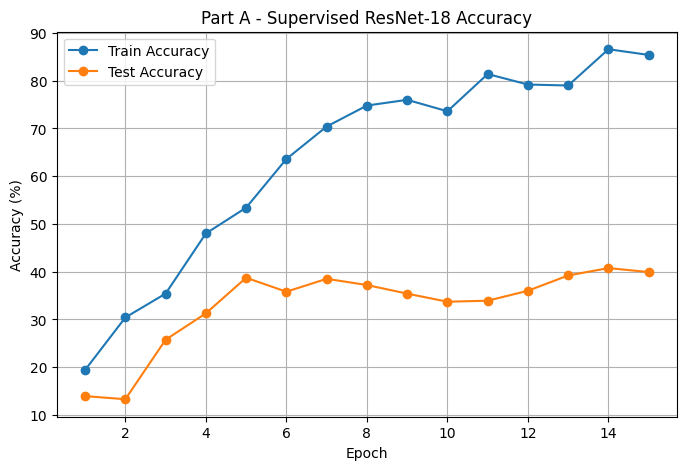

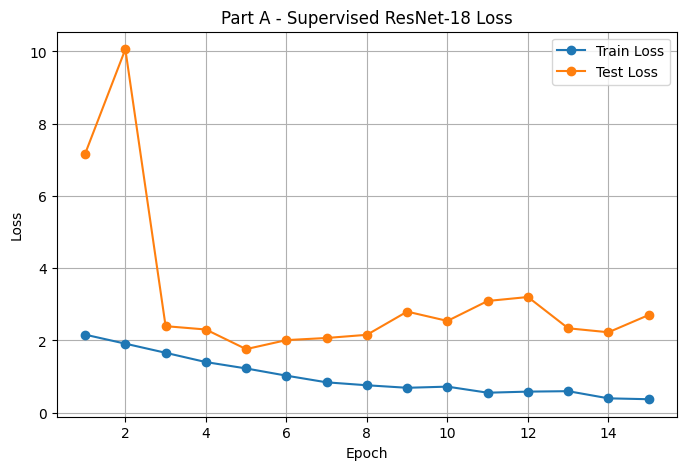

PART A - SUMMARY
Labeled training images : 500
Architecture            : ResNet-18
Pretrained weights      : None
Training epochs         : 15
Final train accuracy    : 85.40%
Final test accuracy     : 39.91%
Best test accuracy      : 40.75%
Best test epoch         : 14
Training time           : 1.55 minutes

Checkpoint saved: HW6_PartA_ResNet18_1980.pt
PASS: Part A complete.


In [8]:
# ============================================================
# HW6 - Part A: Curves, Summary and Checkpoint
# ============================================================

import matplotlib.pyplot as plt
import torch

epochs_A = range(1, EPOCHS_A + 1)

# ------------------------------------------------------------
# Accuracy curve
# ------------------------------------------------------------
plt.figure(figsize=(8, 5))
plt.plot(epochs_A, history_A["train_acc"], marker="o", label="Train Accuracy")
plt.plot(epochs_A, history_A["test_acc"], marker="o", label="Test Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Part A - Supervised ResNet-18 Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# ------------------------------------------------------------
# Loss curve
# ------------------------------------------------------------
plt.figure(figsize=(8, 5))
plt.plot(epochs_A, history_A["train_loss"], marker="o", label="Train Loss")
plt.plot(epochs_A, history_A["test_loss"], marker="o", label="Test Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Part A - Supervised ResNet-18 Loss")
plt.legend()
plt.grid(True)
plt.show()

# ------------------------------------------------------------
# Best epoch
# ------------------------------------------------------------
best_epoch_A = int(np.argmax(history_A["test_acc"])) + 1
best_test_acc_A = max(history_A["test_acc"])

print("=" * 65)
print("PART A - SUMMARY")
print("=" * 65)
print(f"Labeled training images : {len(train_500_A)}")
print(f"Architecture            : ResNet-18")
print(f"Pretrained weights      : None")
print(f"Training epochs         : {EPOCHS_A}")
print(f"Final train accuracy    : {history_A['train_acc'][-1]:.2f}%")
print(f"Final test accuracy     : {final_test_acc_A:.2f}%")
print(f"Best test accuracy      : {best_test_acc_A:.2f}%")
print(f"Best test epoch         : {best_epoch_A}")
print(f"Training time           : {training_time_A / 60:.2f} minutes")
print("=" * 65)

# ------------------------------------------------------------
# Save final checkpoint
# ------------------------------------------------------------
checkpoint_A = {
    "model_state_dict": model_A.state_dict(),
    "optimizer_state_dict": optimizer_A.state_dict(),
    "history": history_A,
    "epochs": EPOCHS_A,
    "final_test_accuracy": final_test_acc_A,
    "best_test_accuracy": best_test_acc_A,
    "best_epoch": best_epoch_A,
    "seed": SEED,
    "subset_indices": indices
}

torch.save(checkpoint_A, "HW6_PartA_ResNet18_1980.pt")

print("\nCheckpoint saved: HW6_PartA_ResNet18_1980.pt")
print("PASS: Part A complete.")

In [9]:
# ============================================================
# HW6 - Part B: Rotation Self-Supervised Dataset
# ============================================================

from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import functional as TF
from torchvision import datasets, transforms
import random

# ------------------------------------------------------------
# Base unlabeled STL-10 dataset
# Keep PIL images so rotation can be applied first
# ------------------------------------------------------------
unlabeled_B = datasets.STL10(
    root="./data",
    split="unlabeled",
    download=False,
    transform=None
)

rotation_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])


class RotationDataset(Dataset):
    """
    Creates a self-supervised rotation prediction task.

    Labels:
        0 ->   0 degrees
        1 ->  90 degrees
        2 -> 180 degrees
        3 -> 270 degrees
    """

    def __init__(self, dataset, transform=None):
        self.dataset = dataset
        self.transform = transform
        self.rotations = [0, 90, 180, 270]

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):

        image, _ = self.dataset[idx]

        # Randomly select one of four rotation classes
        rotation_label = random.randint(0, 3)
        angle = self.rotations[rotation_label]

        # Rotate image
        image = TF.rotate(image, angle)

        if self.transform is not None:
            image = self.transform(image)

        return image, rotation_label


rotation_dataset = RotationDataset(
    unlabeled_B,
    transform=rotation_transform
)

rotation_loader = DataLoader(
    rotation_dataset,
    batch_size=128,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

# ------------------------------------------------------------
# Verification
# ------------------------------------------------------------
rot_images, rot_labels = next(iter(rotation_loader))

print("=" * 65)
print("PART B - ROTATION SSL DATASET")
print("=" * 65)
print(f"Unlabeled images       : {len(unlabeled_B)}")
print(f"Rotation samples       : {len(rotation_dataset)}")
print(f"Batch size             : {rot_images.shape[0]}")
print(f"Image batch shape      : {rot_images.shape}")
print(f"Label batch shape      : {rot_labels.shape}")
print(f"Possible labels        : 0, 1, 2, 3")
print(f"Example batch labels   : {rot_labels[:20].tolist()}")
print("=" * 65)

assert len(rotation_dataset) == 100000
assert rot_images.shape[1:] == (3, 96, 96)
assert rot_labels.min() >= 0
assert rot_labels.max() <= 3

print("\nPASS: Rotation SSL dataset is ready.")

PART B - ROTATION SSL DATASET
Unlabeled images       : 100000
Rotation samples       : 100000
Batch size             : 128
Image batch shape      : torch.Size([128, 3, 96, 96])
Label batch shape      : torch.Size([128])
Possible labels        : 0, 1, 2, 3
Example batch labels   : [3, 3, 2, 1, 3, 0, 2, 2, 0, 3, 2, 0, 2, 3, 0, 0, 0, 0, 3, 2]

PASS: Rotation SSL dataset is ready.


In [10]:
# ============================================================
# HW6 - Part B: Build Rotation Prediction ResNet-18
# ============================================================

import torch.nn as nn
from torchvision.models import resnet18

# New ResNet-18 from scratch for Rotation SSL
model_B_rotation = resnet18(weights=None)

# Rotation prediction has 4 classes:
# 0°, 90°, 180°, 270°
model_B_rotation.fc = nn.Linear(
    model_B_rotation.fc.in_features,
    4
)

model_B_rotation = model_B_rotation.to(device)

# Loss
criterion_B_rotation = nn.CrossEntropyLoss()

# Optimizer
optimizer_B_rotation = torch.optim.Adam(
    model_B_rotation.parameters(),
    lr=1e-3
)

# ------------------------------------------------------------
# Verification
# ------------------------------------------------------------
total_params_B = sum(
    p.numel() for p in model_B_rotation.parameters()
)

trainable_params_B = sum(
    p.numel()
    for p in model_B_rotation.parameters()
    if p.requires_grad
)

print("=" * 65)
print("PART B - ROTATION SSL MODEL")
print("=" * 65)
print("Architecture          : ResNet-18")
print("Pretrained weights    : None")
print("SSL task              : Rotation prediction")
print("Rotation classes      : 4")
print(f"Rotation head         : {model_B_rotation.fc}")
print(f"Total parameters      : {total_params_B:,}")
print(f"Trainable parameters  : {trainable_params_B:,}")
print(f"Device                : {next(model_B_rotation.parameters()).device}")
print("Optimizer             : Adam")
print("Learning rate         : 0.001")
print("=" * 65)

# ------------------------------------------------------------
# Test one batch
# ------------------------------------------------------------
model_B_rotation.eval()

with torch.no_grad():
    sample_rot_images = rot_images[:4].to(device)
    sample_rot_output = model_B_rotation(sample_rot_images)

print(f"\nInput shape  : {sample_rot_images.shape}")
print(f"Output shape : {sample_rot_output.shape}")

assert sample_rot_output.shape == (4, 4)
assert next(model_B_rotation.parameters()).is_cuda

print("\nPASS: Rotation SSL ResNet-18 is correctly configured.")

PART B - ROTATION SSL MODEL
Architecture          : ResNet-18
Pretrained weights    : None
SSL task              : Rotation prediction
Rotation classes      : 4
Rotation head         : Linear(in_features=512, out_features=4, bias=True)
Total parameters      : 11,178,564
Trainable parameters  : 11,178,564
Device                : cuda:0
Optimizer             : Adam
Learning rate         : 0.001

Input shape  : torch.Size([4, 3, 96, 96])
Output shape : torch.Size([4, 4])

PASS: Rotation SSL ResNet-18 is correctly configured.


In [11]:
# ============================================================
# HW6 - Part B: Rotation SSL Training - 15 Epochs
# ============================================================

import time

EPOCHS_B_ROTATION = 15

rotation_history = {
    "loss": [],
    "accuracy": []
}

print("=" * 75)
print("PART B - ROTATION SELF-SUPERVISED TRAINING")
print("=" * 75)
print(f"Unlabeled images : {len(rotation_dataset)}")
print(f"Epochs           : {EPOCHS_B_ROTATION}")
print(f"Batch size       : 128")
print(f"Device           : {device}")
print("=" * 75)

start_time_B_rotation = time.time()

for epoch in range(1, EPOCHS_B_ROTATION + 1):

    model_B_rotation.train()

    running_loss = 0.0
    correct = 0
    total = 0

    epoch_start = time.time()

    for batch_images, batch_labels in rotation_loader:

        batch_images = batch_images.to(
            device,
            non_blocking=True
        )

        batch_labels = batch_labels.to(
            device,
            non_blocking=True
        )

        # Clear gradients
        optimizer_B_rotation.zero_grad()

        # Forward
        outputs = model_B_rotation(batch_images)

        loss = criterion_B_rotation(
            outputs,
            batch_labels
        )

        # Backward
        loss.backward()
        optimizer_B_rotation.step()

        # Metrics
        running_loss += (
            loss.item() * batch_images.size(0)
        )

        predictions = outputs.argmax(dim=1)

        correct += (
            predictions == batch_labels
        ).sum().item()

        total += batch_labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = 100.0 * correct / total
    epoch_time = time.time() - epoch_start

    rotation_history["loss"].append(epoch_loss)
    rotation_history["accuracy"].append(
        epoch_accuracy
    )

    print(
        f"Epoch [{epoch:02d}/{EPOCHS_B_ROTATION}] | "
        f"Loss: {epoch_loss:.4f} | "
        f"Rotation Acc: {epoch_accuracy:6.2f}% | "
        f"Time: {epoch_time:.1f}s"
    )

training_time_B_rotation = (
    time.time() - start_time_B_rotation
)

print("\n" + "=" * 75)
print("ROTATION SSL PRETRAINING COMPLETE")
print("=" * 75)
print(
    f"Final Rotation Loss     : "
    f"{rotation_history['loss'][-1]:.4f}"
)
print(
    f"Final Rotation Accuracy : "
    f"{rotation_history['accuracy'][-1]:.2f}%"
)
print(
    f"Total Training Time     : "
    f"{training_time_B_rotation / 60:.2f} minutes"
)
print("=" * 75)

PART B - ROTATION SELF-SUPERVISED TRAINING
Unlabeled images : 100000
Epochs           : 15
Batch size       : 128
Device           : cuda
Epoch [01/15] | Loss: 0.9276 | Rotation Acc:  61.80% | Time: 85.9s
Epoch [02/15] | Loss: 0.7380 | Rotation Acc:  70.82% | Time: 85.9s
Epoch [03/15] | Loss: 0.6459 | Rotation Acc:  74.85% | Time: 84.9s
Epoch [04/15] | Loss: 0.5812 | Rotation Acc:  77.54% | Time: 85.9s
Epoch [05/15] | Loss: 0.5310 | Rotation Acc:  79.43% | Time: 84.9s
Epoch [06/15] | Loss: 0.4921 | Rotation Acc:  81.07% | Time: 84.6s
Epoch [07/15] | Loss: 0.4594 | Rotation Acc:  82.65% | Time: 85.6s
Epoch [08/15] | Loss: 0.4322 | Rotation Acc:  83.71% | Time: 84.8s
Epoch [09/15] | Loss: 0.4072 | Rotation Acc:  84.75% | Time: 85.5s
Epoch [10/15] | Loss: 0.3845 | Rotation Acc:  85.47% | Time: 85.1s
Epoch [11/15] | Loss: 0.3624 | Rotation Acc:  86.42% | Time: 85.2s
Epoch [12/15] | Loss: 0.3448 | Rotation Acc:  87.17% | Time: 85.0s
Epoch [13/15] | Loss: 0.3279 | Rotation Acc:  87.78% | Tim

In [12]:
# ============================================================
# HW6 - Part B: Freeze Encoder + Linear Evaluation Setup
# ============================================================

import torch.nn as nn

# ------------------------------------------------------------
# Remove the 4-class rotation prediction head
# The remaining ResNet-18 is our learned encoder
# ------------------------------------------------------------
rotation_encoder = model_B_rotation

# Save feature dimension before removing FC layer
feature_dim_B = rotation_encoder.fc.in_features   # 512

# Remove rotation head
rotation_encoder.fc = nn.Identity()

# ------------------------------------------------------------
# Freeze ALL encoder parameters
# ------------------------------------------------------------
for param in rotation_encoder.parameters():
    param.requires_grad = False

rotation_encoder = rotation_encoder.to(device)

# ------------------------------------------------------------
# Linear classifier for STL-10's 10 classes
# ------------------------------------------------------------
linear_classifier_B = nn.Linear(
    feature_dim_B,
    10
).to(device)

criterion_B_linear = nn.CrossEntropyLoss()

# IMPORTANT:
# Optimizer receives ONLY classifier parameters
optimizer_B_linear = torch.optim.Adam(
    linear_classifier_B.parameters(),
    lr=1e-3
)

# ------------------------------------------------------------
# Verification
# ------------------------------------------------------------
encoder_total = sum(
    p.numel() for p in rotation_encoder.parameters()
)

encoder_trainable = sum(
    p.numel()
    for p in rotation_encoder.parameters()
    if p.requires_grad
)

classifier_total = sum(
    p.numel() for p in linear_classifier_B.parameters()
)

classifier_trainable = sum(
    p.numel()
    for p in linear_classifier_B.parameters()
    if p.requires_grad
)

print("=" * 70)
print("PART B - FROZEN ENCODER + LINEAR CLASSIFIER")
print("=" * 70)

print(f"Encoder feature dimension       : {feature_dim_B}")
print(f"Encoder parameters              : {encoder_total:,}")
print(f"Trainable encoder parameters    : {encoder_trainable:,}")

print("-" * 70)

print(f"Linear classifier               : {linear_classifier_B}")
print(f"Classifier parameters           : {classifier_total:,}")
print(f"Trainable classifier parameters : {classifier_trainable:,}")

print("-" * 70)

print(f"Labeled training images         : {len(train_500_A)}")
print(f"Same 500-image subset as Part A : {len(train_500_A) == 500}")

print("=" * 70)

# ------------------------------------------------------------
# Required assignment checks
# ------------------------------------------------------------
assert encoder_trainable == 0
assert classifier_trainable == classifier_total
assert feature_dim_B == 512
assert len(train_500_A) == 500

# Test encoder + classifier
rotation_encoder.eval()

with torch.no_grad():
    sample_images_B = images[:4].to(device)

    features_B = rotation_encoder(sample_images_B)
    logits_B = linear_classifier_B(features_B)

print(f"\nEncoder output shape    : {features_B.shape}")
print(f"Classifier output shape : {logits_B.shape}")

assert features_B.shape == (4, 512)
assert logits_B.shape == (4, 10)

print("\nPASS: Encoder is completely frozen.")
print("PASS: Only the linear classifier can update.")
print("PASS: Part B linear evaluation setup is correct.")

PART B - FROZEN ENCODER + LINEAR CLASSIFIER
Encoder feature dimension       : 512
Encoder parameters              : 11,176,512
Trainable encoder parameters    : 0
----------------------------------------------------------------------
Linear classifier               : Linear(in_features=512, out_features=10, bias=True)
Classifier parameters           : 5,130
Trainable classifier parameters : 5,130
----------------------------------------------------------------------
Labeled training images         : 500
Same 500-image subset as Part A : True

Encoder output shape    : torch.Size([4, 512])
Classifier output shape : torch.Size([4, 10])

PASS: Encoder is completely frozen.
PASS: Only the linear classifier can update.
PASS: Part B linear evaluation setup is correct.


In [13]:
# ============================================================
# HW6 - Part B: Linear Evaluation - 20 Epochs
# Frozen Rotation Encoder
# ============================================================

import time

EPOCHS_B_LINEAR = 20

history_B_linear = {
    "train_loss": [],
    "train_acc": [],
    "test_loss": [],
    "test_acc": []
}

print("=" * 75)
print("PART B - LINEAR EVALUATION")
print("=" * 75)
print(f"Labeled training images      : {len(train_500_A)}")
print(f"Epochs                       : {EPOCHS_B_LINEAR}")
print(f"Trainable encoder parameters : 0")
print(f"Trainable classifier params  : {classifier_trainable:,}")
print(f"Device                       : {device}")
print("=" * 75)

start_time_B_linear = time.time()

for epoch in range(1, EPOCHS_B_LINEAR + 1):

    # Encoder stays frozen and in eval mode
    rotation_encoder.eval()
    linear_classifier_B.train()

    # ---------------- TRAIN ----------------
    running_loss = 0.0
    correct = 0
    total = 0

    for batch_images, batch_labels in train_loader_A:

        batch_images = batch_images.to(device, non_blocking=True)
        batch_labels = batch_labels.to(device, non_blocking=True)

        optimizer_B_linear.zero_grad()

        # No gradients through frozen encoder
        with torch.no_grad():
            features = rotation_encoder(batch_images)

        outputs = linear_classifier_B(features)

        loss = criterion_B_linear(
            outputs,
            batch_labels
        )

        loss.backward()
        optimizer_B_linear.step()

        running_loss += (
            loss.item() * batch_images.size(0)
        )

        predictions = outputs.argmax(dim=1)

        correct += (
            predictions == batch_labels
        ).sum().item()

        total += batch_labels.size(0)

    train_loss = running_loss / total
    train_acc = 100.0 * correct / total

    # ---------------- TEST ----------------
    rotation_encoder.eval()
    linear_classifier_B.eval()

    test_running_loss = 0.0
    test_correct = 0
    test_total = 0

    with torch.no_grad():

        for batch_images, batch_labels in test_loader_A:

            batch_images = batch_images.to(
                device,
                non_blocking=True
            )

            batch_labels = batch_labels.to(
                device,
                non_blocking=True
            )

            features = rotation_encoder(batch_images)

            outputs = linear_classifier_B(features)

            loss = criterion_B_linear(
                outputs,
                batch_labels
            )

            test_running_loss += (
                loss.item() * batch_images.size(0)
            )

            predictions = outputs.argmax(dim=1)

            test_correct += (
                predictions == batch_labels
            ).sum().item()

            test_total += batch_labels.size(0)

    test_loss = test_running_loss / test_total
    test_acc = 100.0 * test_correct / test_total

    # Store history
    history_B_linear["train_loss"].append(train_loss)
    history_B_linear["train_acc"].append(train_acc)
    history_B_linear["test_loss"].append(test_loss)
    history_B_linear["test_acc"].append(test_acc)

    print(
        f"Epoch [{epoch:02d}/{EPOCHS_B_LINEAR}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:6.2f}% | "
        f"Test Loss: {test_loss:.4f} | "
        f"Test Acc: {test_acc:6.2f}%"
    )

training_time_B_linear = (
    time.time() - start_time_B_linear
)

final_test_acc_B = history_B_linear["test_acc"][-1]
best_test_acc_B = max(history_B_linear["test_acc"])
best_epoch_B = (
    int(np.argmax(history_B_linear["test_acc"])) + 1
)

print("\n" + "=" * 75)
print("PART B - LINEAR EVALUATION COMPLETE")
print("=" * 75)
print(
    f"Final Test Accuracy : "
    f"{final_test_acc_B:.2f}%"
)
print(
    f"Best Test Accuracy  : "
    f"{best_test_acc_B:.2f}%"
)
print(
    f"Best Epoch          : "
    f"{best_epoch_B}"
)
print(
    f"Training Time       : "
    f"{training_time_B_linear / 60:.2f} minutes"
)
print("=" * 75)

PART B - LINEAR EVALUATION
Labeled training images      : 500
Epochs                       : 20
Trainable encoder parameters : 0
Trainable classifier params  : 5,130
Device                       : cuda
Epoch [01/20] | Train Loss: 2.2573 | Train Acc:   9.80% | Test Loss: 2.2297 | Test Acc:  14.06%
Epoch [02/20] | Train Loss: 2.1578 | Train Acc:  17.80% | Test Loss: 2.1593 | Test Acc:  16.70%
Epoch [03/20] | Train Loss: 2.1115 | Train Acc:  24.40% | Test Loss: 2.0734 | Test Acc:  29.40%
Epoch [04/20] | Train Loss: 2.0435 | Train Acc:  33.20% | Test Loss: 2.0485 | Test Acc:  31.66%
Epoch [05/20] | Train Loss: 1.9819 | Train Acc:  39.40% | Test Loss: 2.0113 | Test Acc:  32.05%
Epoch [06/20] | Train Loss: 1.9519 | Train Acc:  39.40% | Test Loss: 1.9766 | Test Acc:  34.10%
Epoch [07/20] | Train Loss: 1.9015 | Train Acc:  40.00% | Test Loss: 1.9604 | Test Acc:  33.42%
Epoch [08/20] | Train Loss: 1.8702 | Train Acc:  45.20% | Test Loss: 1.9085 | Test Acc:  35.65%
Epoch [09/20] | Train Loss: 1.

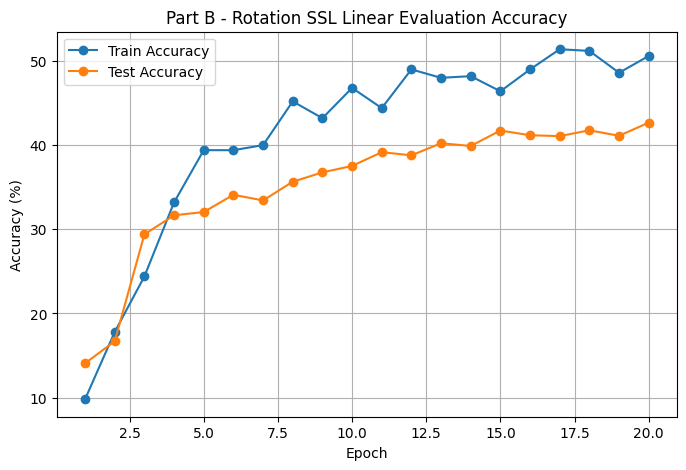

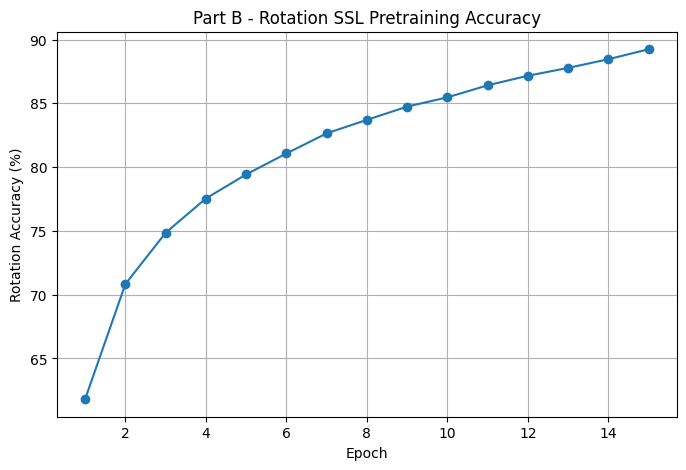

PART B - FINAL SUMMARY
Unlabeled pretraining images : 100000
Rotation pretraining epochs  : 15
Final rotation accuracy      : 89.25%
----------------------------------------------------------------------
Linear evaluation images     : 500
Linear evaluation epochs     : 20
Encoder frozen               : Yes
Trainable encoder parameters : 0
Final test accuracy          : 42.67%
Best test accuracy           : 42.67%
Best epoch                   : 20

Checkpoint saved: HW6_PartB_RotationSSL_1980.pt
PASS: Part B complete.


In [14]:
# ============================================================
# HW6 - Part B: Curves, Summary and Checkpoint
# ============================================================

import matplotlib.pyplot as plt
import torch

epochs_B = range(1, EPOCHS_B_LINEAR + 1)

# ------------------------------------------------------------
# Linear evaluation accuracy
# ------------------------------------------------------------
plt.figure(figsize=(8, 5))

plt.plot(
    epochs_B,
    history_B_linear["train_acc"],
    marker="o",
    label="Train Accuracy"
)

plt.plot(
    epochs_B,
    history_B_linear["test_acc"],
    marker="o",
    label="Test Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Part B - Rotation SSL Linear Evaluation Accuracy")
plt.legend()
plt.grid(True)
plt.show()


# ------------------------------------------------------------
# Rotation SSL pretraining curve
# ------------------------------------------------------------
rotation_epochs = range(1, EPOCHS_B_ROTATION + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    rotation_epochs,
    rotation_history["accuracy"],
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Rotation Accuracy (%)")
plt.title("Part B - Rotation SSL Pretraining Accuracy")
plt.grid(True)
plt.show()


# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------
print("=" * 70)
print("PART B - FINAL SUMMARY")
print("=" * 70)

print(f"Unlabeled pretraining images : {len(rotation_dataset)}")
print(f"Rotation pretraining epochs  : {EPOCHS_B_ROTATION}")
print(
    f"Final rotation accuracy      : "
    f"{rotation_history['accuracy'][-1]:.2f}%"
)

print("-" * 70)

print(f"Linear evaluation images     : {len(train_500_A)}")
print(f"Linear evaluation epochs     : {EPOCHS_B_LINEAR}")
print(f"Encoder frozen               : Yes")
print(f"Trainable encoder parameters : 0")
print(f"Final test accuracy          : {final_test_acc_B:.2f}%")
print(f"Best test accuracy           : {best_test_acc_B:.2f}%")
print(f"Best epoch                   : {best_epoch_B}")

print("=" * 70)


# ------------------------------------------------------------
# Save Part B checkpoint
# ------------------------------------------------------------
checkpoint_B = {
    "encoder_state_dict": rotation_encoder.state_dict(),
    "classifier_state_dict": linear_classifier_B.state_dict(),
    "rotation_history": rotation_history,
    "linear_history": history_B_linear,
    "rotation_epochs": EPOCHS_B_ROTATION,
    "linear_epochs": EPOCHS_B_LINEAR,
    "final_test_accuracy": final_test_acc_B,
    "best_test_accuracy": best_test_acc_B,
    "best_epoch": best_epoch_B,
    "seed": SEED,
    "subset_indices": indices
}

torch.save(
    checkpoint_B,
    "HW6_PartB_RotationSSL_1980.pt"
)

print("\nCheckpoint saved: HW6_PartB_RotationSSL_1980.pt")
print("PASS: Part B complete.")

In [15]:
# ============================================================
# HW6 - Part C: SimCLR Dataset and Augmentations
# ============================================================

from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import datasets, transforms
import torch

# ------------------------------------------------------------
# SimCLR augmentations
# Four main augmentations:
# 1. RandomResizedCrop
# 2. RandomHorizontalFlip
# 3. ColorJitter
# 4. RandomGrayscale
# ------------------------------------------------------------

simclr_transform = transforms.Compose([
    transforms.RandomResizedCrop(
        size=96,
        scale=(0.2, 1.0)
    ),

    transforms.RandomHorizontalFlip(p=0.5),

    transforms.RandomApply(
        [
            transforms.ColorJitter(
                brightness=0.4,
                contrast=0.4,
                saturation=0.4,
                hue=0.1
            )
        ],
        p=0.8
    ),

    transforms.RandomGrayscale(p=0.2),

    transforms.ToTensor(),

    transforms.Normalize(mean, std)
])


# ------------------------------------------------------------
# Dataset that returns TWO independently augmented views
# ------------------------------------------------------------

class SimCLRDataset(Dataset):

    def __init__(self, dataset, transform):
        self.dataset = dataset
        self.transform = transform

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):

        image, _ = self.dataset[idx]

        # Two independent augmented views
        view1 = self.transform(image)
        view2 = self.transform(image)

        return view1, view2


# ------------------------------------------------------------
# Load raw unlabeled STL-10
# ------------------------------------------------------------

unlabeled_C_full = datasets.STL10(
    root="./data",
    split="unlabeled",
    download=False,
    transform=None
)


# ------------------------------------------------------------
# Select exactly 20,000 images reproducibly
# ------------------------------------------------------------

simclr_generator = torch.Generator().manual_seed(SEED)

simclr_indices = torch.randperm(
    len(unlabeled_C_full),
    generator=simclr_generator
)[:20000].tolist()

unlabeled_C_20k = Subset(
    unlabeled_C_full,
    simclr_indices
)


# Wrap subset so each image produces two views
simclr_dataset = SimCLRDataset(
    unlabeled_C_20k,
    simclr_transform
)


# ------------------------------------------------------------
# DataLoader
# ------------------------------------------------------------

SIMCLR_BATCH_SIZE = 128

simclr_loader = DataLoader(
    simclr_dataset,
    batch_size=SIMCLR_BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    drop_last=True,
    generator=torch.Generator().manual_seed(SEED)
)


# ------------------------------------------------------------
# Verification
# ------------------------------------------------------------

view1, view2 = next(iter(simclr_loader))

print("=" * 70)
print("PART C - SIMCLR DATA PREPARATION")
print("=" * 70)

print(f"Full unlabeled STL-10 set : {len(unlabeled_C_full)}")
print(f"Selected SimCLR subset    : {len(simclr_dataset)}")
print(f"Batch size                : {SIMCLR_BATCH_SIZE}")

print("-" * 70)

print(f"View 1 shape              : {view1.shape}")
print(f"View 2 shape              : {view2.shape}")

print("-" * 70)

print("Augmentations:")
print("1. RandomResizedCrop")
print("2. RandomHorizontalFlip")
print("3. ColorJitter")
print("4. RandomGrayscale")

print("=" * 70)


# ------------------------------------------------------------
# Required checks
# ------------------------------------------------------------

assert len(simclr_dataset) == 20000

assert view1.shape == (
    SIMCLR_BATCH_SIZE,
    3,
    96,
    96
)

assert view2.shape == (
    SIMCLR_BATCH_SIZE,
    3,
    96,
    96
)

# Two views should normally differ
mean_difference = torch.mean(
    torch.abs(view1 - view2)
).item()

print(
    f"\nMean difference between two views: "
    f"{mean_difference:.4f}"
)

assert mean_difference > 0

print("\nPASS: 20,000-image SimCLR subset created.")
print("PASS: Two independent augmented views are generated.")
print("PASS: Four required augmentations are configured.")

PART C - SIMCLR DATA PREPARATION
Full unlabeled STL-10 set : 100000
Selected SimCLR subset    : 20000
Batch size                : 128
----------------------------------------------------------------------
View 1 shape              : torch.Size([128, 3, 96, 96])
View 2 shape              : torch.Size([128, 3, 96, 96])
----------------------------------------------------------------------
Augmentations:
1. RandomResizedCrop
2. RandomHorizontalFlip
3. ColorJitter
4. RandomGrayscale

Mean difference between two views: 0.9605

PASS: 20,000-image SimCLR subset created.
PASS: Two independent augmented views are generated.
PASS: Four required augmentations are configured.


In [16]:
# ============================================================
# HW6 - Part C: SimCLR Encoder + Projection Head
# ============================================================

import torch
import torch.nn as nn
from torchvision.models import resnet18

# ------------------------------------------------------------
# ResNet-18 encoder - NO pretrained weights
# ------------------------------------------------------------
simclr_encoder = resnet18(weights=None)

feature_dim_C = simclr_encoder.fc.in_features  # 512

# Remove classification layer
simclr_encoder.fc = nn.Identity()

simclr_encoder = simclr_encoder.to(device)


# ------------------------------------------------------------
# SimCLR MLP Projection Head
# 512 -> 512 -> 128
# ------------------------------------------------------------
projection_dim = 128

projection_head = nn.Sequential(
    nn.Linear(feature_dim_C, 512),
    nn.ReLU(),
    nn.Linear(512, projection_dim)
).to(device)


# ------------------------------------------------------------
# Optimizer
# Train BOTH encoder + projection head during SimCLR pretraining
# ------------------------------------------------------------
optimizer_C = torch.optim.Adam(
    list(simclr_encoder.parameters()) +
    list(projection_head.parameters()),
    lr=1e-3
)


# Assignment-required temperature
TEMPERATURE = 0.2


# ------------------------------------------------------------
# Parameter verification
# ------------------------------------------------------------
encoder_params_C = sum(
    p.numel() for p in simclr_encoder.parameters()
)

projection_params_C = sum(
    p.numel() for p in projection_head.parameters()
)

trainable_encoder_C = sum(
    p.numel()
    for p in simclr_encoder.parameters()
    if p.requires_grad
)

trainable_projection_C = sum(
    p.numel()
    for p in projection_head.parameters()
    if p.requires_grad
)


print("=" * 70)
print("PART C - SIMCLR MODEL")
print("=" * 70)

print("Encoder                  : ResNet-18")
print("Pretrained weights       : None")
print(f"Encoder feature dimension: {feature_dim_C}")
print(f"Projection dimension     : {projection_dim}")
print(f"Projection head          : {projection_head}")

print("-" * 70)

print(f"Encoder parameters       : {encoder_params_C:,}")
print(f"Projection parameters    : {projection_params_C:,}")
print(f"Trainable encoder params : {trainable_encoder_C:,}")
print(f"Trainable projection     : {trainable_projection_C:,}")

print("-" * 70)

print("Similarity               : Cosine similarity")
print(f"Temperature (tau)        : {TEMPERATURE}")
print(f"Device                    : {device}")

print("=" * 70)


# ------------------------------------------------------------
# Forward-pass verification
# ------------------------------------------------------------
simclr_encoder.eval()
projection_head.eval()

with torch.no_grad():

    sample_C = view1[:4].to(device)

    features_C = simclr_encoder(sample_C)

    projections_C = projection_head(features_C)


print(f"\nInput shape      : {sample_C.shape}")
print(f"Feature shape    : {features_C.shape}")
print(f"Projection shape : {projections_C.shape}")


assert features_C.shape == (4, 512)
assert projections_C.shape == (4, 128)
assert TEMPERATURE == 0.2

print("\nPASS: SimCLR ResNet-18 encoder is ready.")
print("PASS: MLP projection head is ready.")
print("PASS: Temperature tau = 0.2.")

PART C - SIMCLR MODEL
Encoder                  : ResNet-18
Pretrained weights       : None
Encoder feature dimension: 512
Projection dimension     : 128
Projection head          : Sequential(
  (0): Linear(in_features=512, out_features=512, bias=True)
  (1): ReLU()
  (2): Linear(in_features=512, out_features=128, bias=True)
)
----------------------------------------------------------------------
Encoder parameters       : 11,176,512
Projection parameters    : 328,320
Trainable encoder params : 11,176,512
Trainable projection     : 328,320
----------------------------------------------------------------------
Similarity               : Cosine similarity
Temperature (tau)        : 0.2
Device                    : cuda

Input shape      : torch.Size([4, 3, 96, 96])
Feature shape    : torch.Size([4, 512])
Projection shape : torch.Size([4, 128])

PASS: SimCLR ResNet-18 encoder is ready.
PASS: MLP projection head is ready.
PASS: Temperature tau = 0.2.


In [17]:
# ============================================================
# HW6 - Part C: NT-Xent Contrastive Loss
# Cosine Similarity + Temperature = 0.2
# ============================================================

import torch
import torch.nn.functional as F


def nt_xent_loss(z1, z2, temperature=0.2):
    """
    SimCLR NT-Xent loss.

    z1 and z2 are projection vectors from two augmented
    views of the same batch of images.
    """

    batch_size = z1.size(0)

    # --------------------------------------------------------
    # L2 normalize projection vectors.
    # Dot product after normalization = cosine similarity.
    # --------------------------------------------------------
    z1 = F.normalize(z1, dim=1)
    z2 = F.normalize(z2, dim=1)

    # Combine both views:
    # [2N, projection_dim]
    z = torch.cat([z1, z2], dim=0)

    # --------------------------------------------------------
    # Cosine similarity matrix
    # --------------------------------------------------------
    similarity_matrix = torch.matmul(z, z.T)

    # Apply required temperature tau = 0.2
    similarity_matrix = similarity_matrix / temperature

    # --------------------------------------------------------
    # Remove self-similarity from denominator
    # --------------------------------------------------------
    mask = torch.eye(
        2 * batch_size,
        dtype=torch.bool,
        device=z.device
    )

    similarity_matrix = similarity_matrix.masked_fill(
        mask,
        -1e9
    )

    # --------------------------------------------------------
    # Positive pair labels
    #
    # For sample i in view 1, positive is i + N.
    # For sample i in view 2, positive is i.
    # --------------------------------------------------------
    positive_targets = torch.arange(
        2 * batch_size,
        device=z.device
    )

    positive_targets = (
        positive_targets + batch_size
    ) % (2 * batch_size)

    # Cross entropy over similarity scores
    loss = F.cross_entropy(
        similarity_matrix,
        positive_targets
    )

    return loss


# ------------------------------------------------------------
# Verify loss using one batch
# ------------------------------------------------------------

simclr_encoder.train()
projection_head.train()

test_view1 = view1.to(device)
test_view2 = view2.to(device)

with torch.no_grad():

    h1 = simclr_encoder(test_view1)
    h2 = simclr_encoder(test_view2)

    z1 = projection_head(h1)
    z2 = projection_head(h2)

    test_contrastive_loss = nt_xent_loss(
        z1,
        z2,
        temperature=TEMPERATURE
    )


print("=" * 70)
print("PART C - NT-XENT LOSS VERIFICATION")
print("=" * 70)

print(f"Batch size              : {test_view1.size(0)}")
print(f"Projection z1 shape     : {z1.shape}")
print(f"Projection z2 shape     : {z2.shape}")
print("Similarity              : Cosine similarity")
print(f"Temperature tau         : {TEMPERATURE}")
print(f"Initial contrastive loss: {test_contrastive_loss.item():.4f}")

print("=" * 70)


# Required checks
assert z1.shape == (SIMCLR_BATCH_SIZE, 128)
assert z2.shape == (SIMCLR_BATCH_SIZE, 128)
assert TEMPERATURE == 0.2
assert torch.isfinite(test_contrastive_loss)

print("\nPASS: NT-Xent loss is finite.")
print("PASS: Cosine similarity is implemented using L2 normalization.")
print("PASS: Temperature tau = 0.2 is applied.")

PART C - NT-XENT LOSS VERIFICATION
Batch size              : 128
Projection z1 shape     : torch.Size([128, 128])
Projection z2 shape     : torch.Size([128, 128])
Similarity              : Cosine similarity
Temperature tau         : 0.2
Initial contrastive loss: 5.4450

PASS: NT-Xent loss is finite.
PASS: Cosine similarity is implemented using L2 normalization.
PASS: Temperature tau = 0.2 is applied.


In [18]:
# ============================================================
# HW6 - Part C: SimCLR Pretraining - 20 Epochs
# ============================================================

import time

EPOCHS_C = 20

simclr_history = {
    "loss": []
}

print("=" * 75)
print("PART C - SIMCLR CONTRASTIVE PRETRAINING")
print("=" * 75)
print(f"Unlabeled images : {len(simclr_dataset)}")
print(f"Epochs           : {EPOCHS_C}")
print(f"Batch size       : {SIMCLR_BATCH_SIZE}")
print(f"Temperature tau  : {TEMPERATURE}")
print(f"Device           : {device}")
print("=" * 75)

start_time_C = time.time()

for epoch in range(1, EPOCHS_C + 1):

    simclr_encoder.train()
    projection_head.train()

    running_loss = 0.0
    total_batches = 0

    epoch_start = time.time()

    for batch_view1, batch_view2 in simclr_loader:

        batch_view1 = batch_view1.to(
            device,
            non_blocking=True
        )

        batch_view2 = batch_view2.to(
            device,
            non_blocking=True
        )

        # Clear gradients
        optimizer_C.zero_grad()

        # ----------------------------------------------------
        # Encoder
        # ----------------------------------------------------
        h1 = simclr_encoder(batch_view1)
        h2 = simclr_encoder(batch_view2)

        # ----------------------------------------------------
        # Projection head
        # ----------------------------------------------------
        z1 = projection_head(h1)
        z2 = projection_head(h2)

        # ----------------------------------------------------
        # Contrastive loss
        # ----------------------------------------------------
        loss = nt_xent_loss(
            z1,
            z2,
            temperature=TEMPERATURE
        )

        # Backpropagation
        loss.backward()
        optimizer_C.step()

        running_loss += loss.item()
        total_batches += 1

    epoch_loss = running_loss / total_batches
    epoch_time = time.time() - epoch_start

    simclr_history["loss"].append(epoch_loss)

    print(
        f"Epoch [{epoch:02d}/{EPOCHS_C}] | "
        f"Contrastive Loss: {epoch_loss:.4f} | "
        f"Time: {epoch_time:.1f}s"
    )


training_time_C = time.time() - start_time_C


print("\n" + "=" * 75)
print("SIMCLR PRETRAINING COMPLETE")
print("=" * 75)

print(
    f"Initial Epoch Loss : "
    f"{simclr_history['loss'][0]:.4f}"
)

print(
    f"Final Epoch Loss   : "
    f"{simclr_history['loss'][-1]:.4f}"
)

print(
    f"Total Training Time: "
    f"{training_time_C / 60:.2f} minutes"
)

print("=" * 75)

PART C - SIMCLR CONTRASTIVE PRETRAINING
Unlabeled images : 20000
Epochs           : 20
Batch size       : 128
Temperature tau  : 0.2
Device           : cuda
Epoch [01/20] | Contrastive Loss: 4.3528 | Time: 77.2s
Epoch [02/20] | Contrastive Loss: 3.7243 | Time: 76.6s
Epoch [03/20] | Contrastive Loss: 3.3553 | Time: 77.3s
Epoch [04/20] | Contrastive Loss: 3.0749 | Time: 75.8s
Epoch [05/20] | Contrastive Loss: 2.9006 | Time: 77.1s
Epoch [06/20] | Contrastive Loss: 2.7864 | Time: 75.3s
Epoch [07/20] | Contrastive Loss: 2.6882 | Time: 76.4s
Epoch [08/20] | Contrastive Loss: 2.6242 | Time: 77.0s
Epoch [09/20] | Contrastive Loss: 2.5715 | Time: 77.0s
Epoch [10/20] | Contrastive Loss: 2.5189 | Time: 75.0s
Epoch [11/20] | Contrastive Loss: 2.4721 | Time: 77.2s
Epoch [12/20] | Contrastive Loss: 2.4410 | Time: 75.8s
Epoch [13/20] | Contrastive Loss: 2.4126 | Time: 75.6s
Epoch [14/20] | Contrastive Loss: 2.3510 | Time: 76.2s
Epoch [15/20] | Contrastive Loss: 2.3246 | Time: 77.1s
Epoch [16/20] | Co

In [19]:
# ============================================================
# HW6 - Part C: Freeze SimCLR Encoder + Linear Evaluation Setup
# ============================================================

import torch.nn as nn

# ------------------------------------------------------------
# Projection head is NOT used during linear evaluation.
# Keep only the trained ResNet-18 encoder.
# ------------------------------------------------------------

# Freeze entire SimCLR encoder
for param in simclr_encoder.parameters():
    param.requires_grad = False

simclr_encoder = simclr_encoder.to(device)

# ------------------------------------------------------------
# New 10-class linear classifier
# 512-dimensional encoder features -> 10 STL-10 classes
# ------------------------------------------------------------

linear_classifier_C = nn.Linear(
    feature_dim_C,
    10
).to(device)

criterion_C_linear = nn.CrossEntropyLoss()

# IMPORTANT:
# Optimizer contains ONLY the linear classifier parameters
optimizer_C_linear = torch.optim.Adam(
    linear_classifier_C.parameters(),
    lr=1e-3
)

# ------------------------------------------------------------
# Parameter verification
# ------------------------------------------------------------

encoder_total_C = sum(
    p.numel()
    for p in simclr_encoder.parameters()
)

encoder_trainable_C = sum(
    p.numel()
    for p in simclr_encoder.parameters()
    if p.requires_grad
)

classifier_total_C = sum(
    p.numel()
    for p in linear_classifier_C.parameters()
)

classifier_trainable_C = sum(
    p.numel()
    for p in linear_classifier_C.parameters()
    if p.requires_grad
)

print("=" * 70)
print("PART C - FROZEN SIMCLR ENCODER + LINEAR CLASSIFIER")
print("=" * 70)

print(f"Encoder feature dimension       : {feature_dim_C}")
print(f"Encoder parameters              : {encoder_total_C:,}")
print(f"Trainable encoder parameters    : {encoder_trainable_C:,}")

print("-" * 70)

print(f"Linear classifier               : {linear_classifier_C}")
print(f"Classifier parameters           : {classifier_total_C:,}")
print(f"Trainable classifier parameters : {classifier_trainable_C:,}")

print("-" * 70)

print(f"Labeled training images         : {len(train_500_A)}")
print(f"Same 500-image subset as Part A : {len(train_500_A) == 500}")
print("Projection head used            : No")

print("=" * 70)

# ------------------------------------------------------------
# Required checks
# ------------------------------------------------------------

assert encoder_trainable_C == 0
assert classifier_trainable_C == classifier_total_C
assert feature_dim_C == 512
assert len(train_500_A) == 500

# ------------------------------------------------------------
# Forward-pass verification
# ------------------------------------------------------------

simclr_encoder.eval()

with torch.no_grad():

    sample_images_C = images[:4].to(device)

    features_linear_C = simclr_encoder(
        sample_images_C
    )

    logits_C = linear_classifier_C(
        features_linear_C
    )

print(
    f"\nEncoder output shape    : "
    f"{features_linear_C.shape}"
)

print(
    f"Classifier output shape : "
    f"{logits_C.shape}"
)

assert features_linear_C.shape == (4, 512)
assert logits_C.shape == (4, 10)

print("\nPASS: SimCLR encoder is completely frozen.")
print("PASS: Projection head has been removed from evaluation.")
print("PASS: Only the linear classifier can update.")
print("PASS: Part C linear evaluation setup is correct.")

PART C - FROZEN SIMCLR ENCODER + LINEAR CLASSIFIER
Encoder feature dimension       : 512
Encoder parameters              : 11,176,512
Trainable encoder parameters    : 0
----------------------------------------------------------------------
Linear classifier               : Linear(in_features=512, out_features=10, bias=True)
Classifier parameters           : 5,130
Trainable classifier parameters : 5,130
----------------------------------------------------------------------
Labeled training images         : 500
Same 500-image subset as Part A : True
Projection head used            : No

Encoder output shape    : torch.Size([4, 512])
Classifier output shape : torch.Size([4, 10])

PASS: SimCLR encoder is completely frozen.
PASS: Projection head has been removed from evaluation.
PASS: Only the linear classifier can update.
PASS: Part C linear evaluation setup is correct.


In [20]:
# ============================================================
# HW6 - Part C: SimCLR Linear Evaluation - 20 Epochs
# ============================================================

import time

EPOCHS_C_LINEAR = 20

history_C_linear = {
    "train_loss": [],
    "train_acc": [],
    "test_loss": [],
    "test_acc": []
}

print("=" * 75)
print("PART C - SIMCLR LINEAR EVALUATION")
print("=" * 75)
print(f"Labeled training images      : {len(train_500_A)}")
print(f"Epochs                       : {EPOCHS_C_LINEAR}")
print(f"Trainable encoder parameters : {encoder_trainable_C}")
print(f"Trainable classifier params  : {classifier_trainable_C:,}")
print(f"Projection head used         : No")
print(f"Device                       : {device}")
print("=" * 75)

start_time_C_linear = time.time()

for epoch in range(1, EPOCHS_C_LINEAR + 1):

    # Encoder must remain frozen
    simclr_encoder.eval()
    linear_classifier_C.train()

    # ========================================================
    # TRAIN
    # ========================================================
    running_loss = 0.0
    correct = 0
    total = 0

    for batch_images, batch_labels in train_loader_A:

        batch_images = batch_images.to(
            device,
            non_blocking=True
        )

        batch_labels = batch_labels.to(
            device,
            non_blocking=True
        )

        optimizer_C_linear.zero_grad()

        # Frozen encoder
        with torch.no_grad():
            features = simclr_encoder(batch_images)

        # Only classifier receives gradients
        outputs = linear_classifier_C(features)

        loss = criterion_C_linear(
            outputs,
            batch_labels
        )

        loss.backward()
        optimizer_C_linear.step()

        running_loss += (
            loss.item() * batch_images.size(0)
        )

        predictions = outputs.argmax(dim=1)

        correct += (
            predictions == batch_labels
        ).sum().item()

        total += batch_labels.size(0)

    train_loss = running_loss / total
    train_acc = 100.0 * correct / total

    # ========================================================
    # TEST
    # ========================================================
    simclr_encoder.eval()
    linear_classifier_C.eval()

    test_running_loss = 0.0
    test_correct = 0
    test_total = 0

    with torch.no_grad():

        for batch_images, batch_labels in test_loader_A:

            batch_images = batch_images.to(
                device,
                non_blocking=True
            )

            batch_labels = batch_labels.to(
                device,
                non_blocking=True
            )

            features = simclr_encoder(batch_images)

            outputs = linear_classifier_C(features)

            loss = criterion_C_linear(
                outputs,
                batch_labels
            )

            test_running_loss += (
                loss.item() * batch_images.size(0)
            )

            predictions = outputs.argmax(dim=1)

            test_correct += (
                predictions == batch_labels
            ).sum().item()

            test_total += batch_labels.size(0)

    test_loss = test_running_loss / test_total
    test_acc = 100.0 * test_correct / test_total

    # Save history
    history_C_linear["train_loss"].append(train_loss)
    history_C_linear["train_acc"].append(train_acc)
    history_C_linear["test_loss"].append(test_loss)
    history_C_linear["test_acc"].append(test_acc)

    print(
        f"Epoch [{epoch:02d}/{EPOCHS_C_LINEAR}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:6.2f}% | "
        f"Test Loss: {test_loss:.4f} | "
        f"Test Acc: {test_acc:6.2f}%"
    )


training_time_C_linear = (
    time.time() - start_time_C_linear
)

final_test_acc_C = history_C_linear["test_acc"][-1]

best_test_acc_C = max(
    history_C_linear["test_acc"]
)

best_epoch_C = (
    int(np.argmax(history_C_linear["test_acc"])) + 1
)


print("\n" + "=" * 75)
print("PART C - LINEAR EVALUATION COMPLETE")
print("=" * 75)

print(
    f"Final Test Accuracy : "
    f"{final_test_acc_C:.2f}%"
)

print(
    f"Best Test Accuracy  : "
    f"{best_test_acc_C:.2f}%"
)

print(
    f"Best Epoch          : "
    f"{best_epoch_C}"
)

print(
    f"Training Time       : "
    f"{training_time_C_linear / 60:.2f} minutes"
)

print("=" * 75)

PART C - SIMCLR LINEAR EVALUATION
Labeled training images      : 500
Epochs                       : 20
Trainable encoder parameters : 0
Trainable classifier params  : 5,130
Projection head used         : No
Device                       : cuda
Epoch [01/20] | Train Loss: 2.0653 | Train Acc:  20.80% | Test Loss: 1.7360 | Test Acc:  38.56%
Epoch [02/20] | Train Loss: 1.5169 | Train Acc:  45.20% | Test Loss: 1.4949 | Test Acc:  45.15%
Epoch [03/20] | Train Loss: 1.2988 | Train Acc:  53.00% | Test Loss: 1.3794 | Test Acc:  50.98%
Epoch [04/20] | Train Loss: 1.1979 | Train Acc:  57.60% | Test Loss: 1.3610 | Test Acc:  50.65%
Epoch [05/20] | Train Loss: 1.1172 | Train Acc:  60.00% | Test Loss: 1.3300 | Test Acc:  51.73%
Epoch [06/20] | Train Loss: 1.0666 | Train Acc:  62.80% | Test Loss: 1.3184 | Test Acc:  52.27%
Epoch [07/20] | Train Loss: 1.0523 | Train Acc:  63.60% | Test Loss: 1.3163 | Test Acc:  51.80%
Epoch [08/20] | Train Loss: 1.0056 | Train Acc:  64.40% | Test Loss: 1.3107 | Test Ac

In [21]:
# ============================================================
# HW6 - Part C: Save SimCLR Checkpoint
# ============================================================

checkpoint_C = {
    "simclr_encoder_state_dict": simclr_encoder.state_dict(),
    "linear_classifier_state_dict": linear_classifier_C.state_dict(),

    "simclr_history": simclr_history,
    "linear_history": history_C_linear,

    "simclr_epochs": EPOCHS_C,
    "linear_epochs": EPOCHS_C_LINEAR,

    "temperature": TEMPERATURE,
    "projection_dim": projection_dim,

    "unlabeled_subset_size": len(simclr_dataset),
    "labeled_subset_size": len(train_500_A),

    "final_test_accuracy": final_test_acc_C,
    "best_test_accuracy": best_test_acc_C,
    "best_epoch": best_epoch_C,

    "seed": SEED,
    "simclr_indices": simclr_indices,
    "labeled_indices": indices
}

torch.save(
    checkpoint_C,
    "HW6_PartC_SimCLR_1980.pt"
)

print("=" * 70)
print("PART C - CHECKPOINT SAVED")
print("=" * 70)
print("File                : HW6_PartC_SimCLR_1980.pt")
print(f"Final Test Accuracy : {final_test_acc_C:.2f}%")
print(f"Best Test Accuracy  : {best_test_acc_C:.2f}%")
print(f"Best Epoch          : {best_epoch_C}")
print("=" * 70)

print("\nPASS: Part C complete.")

PART C - CHECKPOINT SAVED
File                : HW6_PartC_SimCLR_1980.pt
Final Test Accuracy : 52.89%
Best Test Accuracy  : 53.40%
Best Epoch          : 12

PASS: Part C complete.


In [23]:
# ============================================================
# HW6 - Part D: Prepare Three Encoders
# ============================================================

import torch
import torch.nn as nn

# ------------------------------------------------------------
# A. Supervised encoder
# model_A currently has its 10-class FC classifier.
# Create feature extractor using everything before FC.
# ------------------------------------------------------------

supervised_encoder = nn.Sequential(
    *list(model_A.children())[:-1]
).to(device)

supervised_encoder.eval()


# ------------------------------------------------------------
# B. Rotation SSL encoder
# rotation_encoder already has fc = Identity()
# ------------------------------------------------------------

rotation_encoder.eval()


# ------------------------------------------------------------
# C. SimCLR encoder
# Projection head is NOT used.
# simclr_encoder already has fc = Identity()
# ------------------------------------------------------------

simclr_encoder.eval()


# ------------------------------------------------------------
# Verify all three produce 512-D representations
# ------------------------------------------------------------

sample_D = images[:4].to(device)

with torch.no_grad():

    # Supervised output is [B, 512, 1, 1]
    feat_A = supervised_encoder(sample_D)
    feat_A = torch.flatten(feat_A, 1)

    # Rotation and SimCLR directly produce [B, 512]
    feat_B = rotation_encoder(sample_D)
    feat_C = simclr_encoder(sample_D)


print("=" * 70)
print("PART D - ENCODER VERIFICATION")
print("=" * 70)

print(f"Supervised features : {feat_A.shape}")
print(f"Rotation features   : {feat_B.shape}")
print(f"SimCLR features     : {feat_C.shape}")

print("-" * 70)

print("Supervised classifier removed : Yes")
print("Rotation classifier removed   : Yes")
print("SimCLR projection head used   : No")

print("=" * 70)


assert feat_A.shape == (4, 512)
assert feat_B.shape == (4, 512)
assert feat_C.shape == (4, 512)

print("\nPASS: All three encoders produce 512-D embeddings.")
print("PASS: Part D will compare encoder representations only.")

PART D - ENCODER VERIFICATION
Supervised features : torch.Size([4, 512])
Rotation features   : torch.Size([4, 512])
SimCLR features     : torch.Size([4, 512])
----------------------------------------------------------------------
Supervised classifier removed : Yes
Rotation classifier removed   : Yes
SimCLR projection head used   : No

PASS: All three encoders produce 512-D embeddings.
PASS: Part D will compare encoder representations only.


In [24]:
# ============================================================
# HW6 - Part D: Extract Test Embeddings
# ============================================================

import torch
import torch.nn.functional as F

supervised_encoder.eval()
rotation_encoder.eval()
simclr_encoder.eval()

features_A_all = []
features_B_all = []
features_C_all = []
labels_all = []

with torch.no_grad():

    for batch_images, batch_labels in test_loader_A:

        batch_images = batch_images.to(
            device,
            non_blocking=True
        )

        # ----------------------------
        # Supervised encoder
        # ----------------------------
        fA = supervised_encoder(batch_images)
        fA = torch.flatten(fA, 1)

        # ----------------------------
        # Rotation SSL encoder
        # ----------------------------
        fB = rotation_encoder(batch_images)

        # ----------------------------
        # SimCLR encoder
        # ----------------------------
        fC = simclr_encoder(batch_images)

        # L2 normalize so dot product = cosine similarity
        fA = F.normalize(fA, dim=1)
        fB = F.normalize(fB, dim=1)
        fC = F.normalize(fC, dim=1)

        features_A_all.append(fA.cpu())
        features_B_all.append(fB.cpu())
        features_C_all.append(fC.cpu())

        labels_all.append(batch_labels)


# Combine batches
features_A_all = torch.cat(features_A_all, dim=0)
features_B_all = torch.cat(features_B_all, dim=0)
features_C_all = torch.cat(features_C_all, dim=0)

labels_all = torch.cat(labels_all, dim=0)


print("=" * 70)
print("PART D - TEST EMBEDDINGS")
print("=" * 70)

print(f"Test images            : {len(labels_all)}")
print(f"Supervised embeddings  : {features_A_all.shape}")
print(f"Rotation embeddings    : {features_B_all.shape}")
print(f"SimCLR embeddings      : {features_C_all.shape}")

print("-" * 70)

print("Embedding dimension    : 512")
print("Normalization          : L2")
print("Similarity for k-NN    : Cosine similarity")

print("=" * 70)


assert features_A_all.shape == (8000, 512)
assert features_B_all.shape == (8000, 512)
assert features_C_all.shape == (8000, 512)
assert labels_all.shape == (8000,)

print("\nPASS: Embeddings extracted for all 8,000 test images.")
print("PASS: All embeddings are ready for cosine nearest-neighbor retrieval.")

PART D - TEST EMBEDDINGS
Test images            : 8000
Supervised embeddings  : torch.Size([8000, 512])
Rotation embeddings    : torch.Size([8000, 512])
SimCLR embeddings      : torch.Size([8000, 512])
----------------------------------------------------------------------
Embedding dimension    : 512
Normalization          : L2
Similarity for k-NN    : Cosine similarity

PASS: Embeddings extracted for all 8,000 test images.
PASS: All embeddings are ready for cosine nearest-neighbor retrieval.


In [25]:
# ============================================================
# HW6 - Part D: Select Same 3 Query Images for All Encoders
# ============================================================

class_names = test_A.classes

# Choose three different classes
query_classes = [0, 1, 2]   # airplane, bird, car

query_indices = []

for class_id in query_classes:

    # Find first test image belonging to this class
    idx = torch.where(labels_all == class_id)[0][0].item()

    query_indices.append(idx)


print("=" * 70)
print("PART D - QUERY IMAGE SELECTION")
print("=" * 70)

for i, idx in enumerate(query_indices, start=1):

    label_id = labels_all[idx].item()

    print(
        f"Query {i}: "
        f"Test index = {idx:4d} | "
        f"Class = {class_names[label_id]} "
        f"(label {label_id})"
    )

print("-" * 70)
print("Same query indices will be used for:")
print("  1. Supervised encoder")
print("  2. Rotation SSL encoder")
print("  3. SimCLR encoder")
print("=" * 70)


assert len(query_indices) == 3
assert len(set(query_indices)) == 3

print("\nPASS: Three fixed query images selected.")
print("PASS: Identical queries will be used for all three encoders.")

PART D - QUERY IMAGE SELECTION
Query 1: Test index =    3 | Class = airplane (label 0)
Query 2: Test index =    5 | Class = bird (label 1)
Query 3: Test index =   24 | Class = car (label 2)
----------------------------------------------------------------------
Same query indices will be used for:
  1. Supervised encoder
  2. Rotation SSL encoder
  3. SimCLR encoder

PASS: Three fixed query images selected.
PASS: Identical queries will be used for all three encoders.


In [26]:
# ============================================================
# HW6 - Part D: Top-5 Cosine Nearest Neighbors
# ============================================================

def get_top5_neighbors(features, query_idx, k=5):

    # Since embeddings are already L2 normalized,
    # dot product = cosine similarity
    query_feature = features[query_idx]

    similarities = torch.matmul(
        features,
        query_feature
    )

    # Do NOT retrieve the query image itself
    similarities[query_idx] = -float("inf")

    # Top-k most similar images
    top_values, top_indices = torch.topk(
        similarities,
        k=k
    )

    return top_indices, top_values


# Store results
neighbor_results = {}

encoders_D = {
    "Supervised": features_A_all,
    "Rotation SSL": features_B_all,
    "SimCLR": features_C_all
}


print("=" * 75)
print("PART D - TOP-5 COSINE NEAREST NEIGHBORS")
print("=" * 75)


for query_idx in query_indices:

    query_label = labels_all[query_idx].item()
    query_class = class_names[query_label]

    neighbor_results[query_idx] = {}

    print(
        f"\nQUERY index={query_idx} | "
        f"class={query_class}"
    )

    for encoder_name, features in encoders_D.items():

        neighbor_indices, similarities = get_top5_neighbors(
            features,
            query_idx,
            k=5
        )

        neighbor_results[query_idx][encoder_name] = {
            "indices": neighbor_indices,
            "similarities": similarities
        }

        neighbor_classes = [
            class_names[labels_all[idx].item()]
            for idx in neighbor_indices
        ]

        print(f"\n  {encoder_name}")

        for rank, (idx, sim, cls) in enumerate(
            zip(
                neighbor_indices.tolist(),
                similarities.tolist(),
                neighbor_classes
            ),
            start=1
        ):
            print(
                f"    {rank}. "
                f"index={idx:4d} | "
                f"class={cls:8s} | "
                f"cosine={sim:.4f}"
            )


print("\n" + "=" * 75)

# Verification
for query_idx in query_indices:

    for encoder_name in encoders_D:

        retrieved = (
            neighbor_results[query_idx]
            [encoder_name]["indices"]
        )

        assert len(retrieved) == 5
        assert query_idx not in retrieved.tolist()

print("PASS: Top-5 neighbors retrieved for every query and encoder.")
print("PASS: Query image itself is excluded from retrieval.")
print("PASS: Cosine similarity used for all comparisons.")

PART D - TOP-5 COSINE NEAREST NEIGHBORS

QUERY index=3 | class=airplane

  Supervised
    1. index=5859 | class=ship     | cosine=0.9678
    2. index=5138 | class=airplane | cosine=0.9611
    3. index= 842 | class=ship     | cosine=0.9610
    4. index=5525 | class=ship     | cosine=0.9599
    5. index=5997 | class=airplane | cosine=0.9587

  Rotation SSL
    1. index=4459 | class=airplane | cosine=0.9833
    2. index=5426 | class=airplane | cosine=0.9810
    3. index=3469 | class=airplane | cosine=0.9800
    4. index=3264 | class=airplane | cosine=0.9796
    5. index=6412 | class=truck    | cosine=0.9793

  SimCLR
    1. index= 414 | class=ship     | cosine=0.9495
    2. index=3280 | class=ship     | cosine=0.9464
    3. index=4756 | class=ship     | cosine=0.9419
    4. index= 240 | class=ship     | cosine=0.9385
    5. index=2439 | class=ship     | cosine=0.9331

QUERY index=5 | class=bird

  Supervised
    1. index=6951 | class=dog      | cosine=0.9681
    2. index=6519 | class=dog 

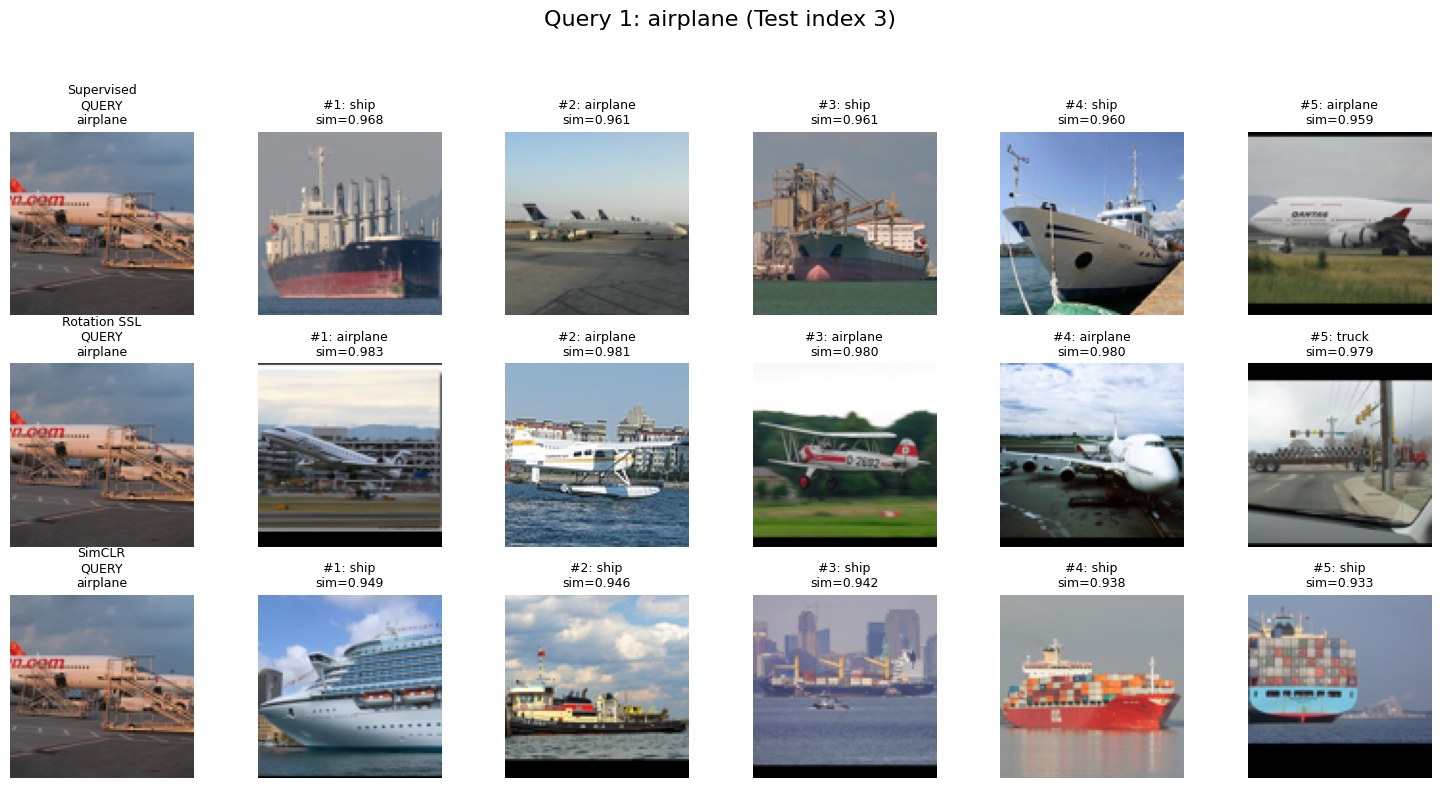

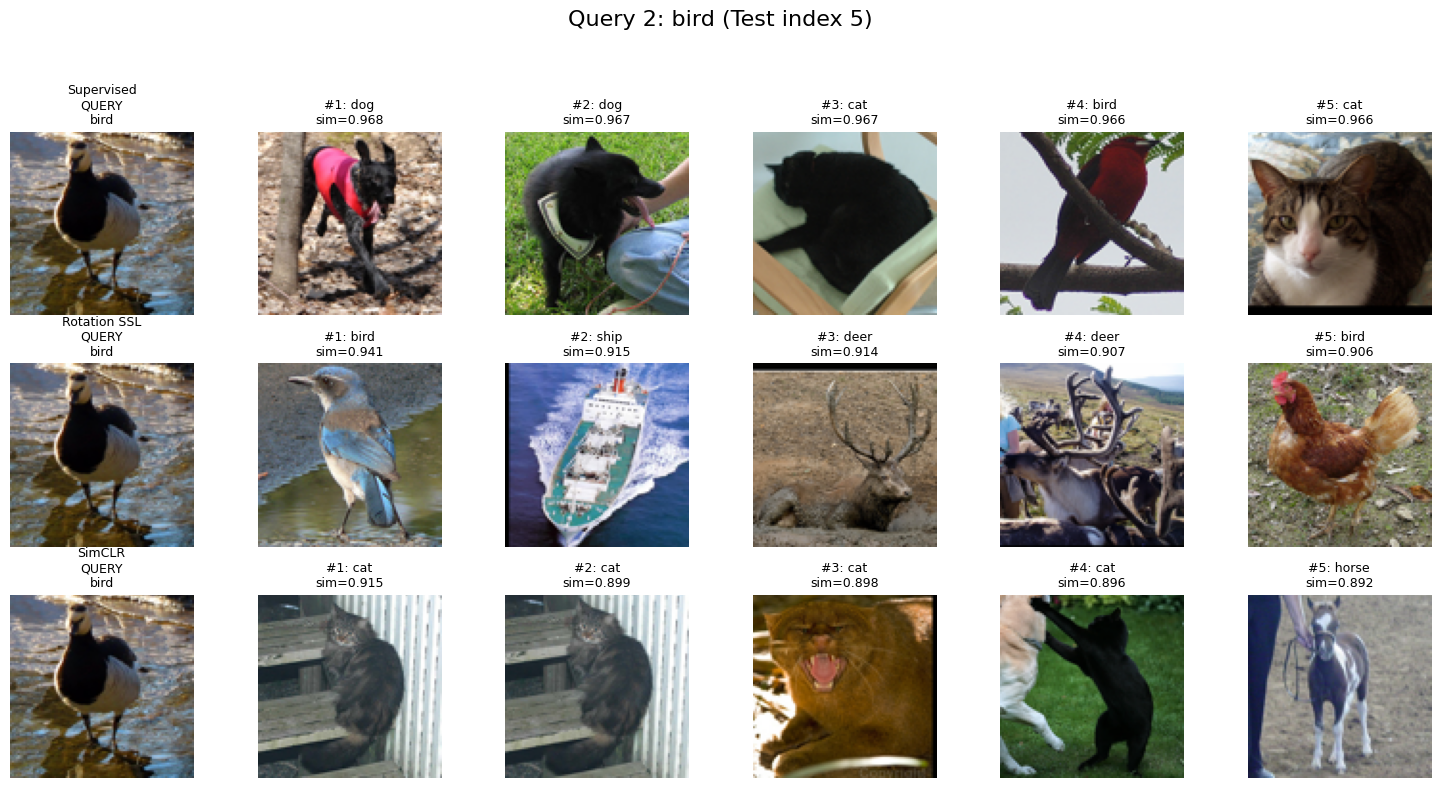

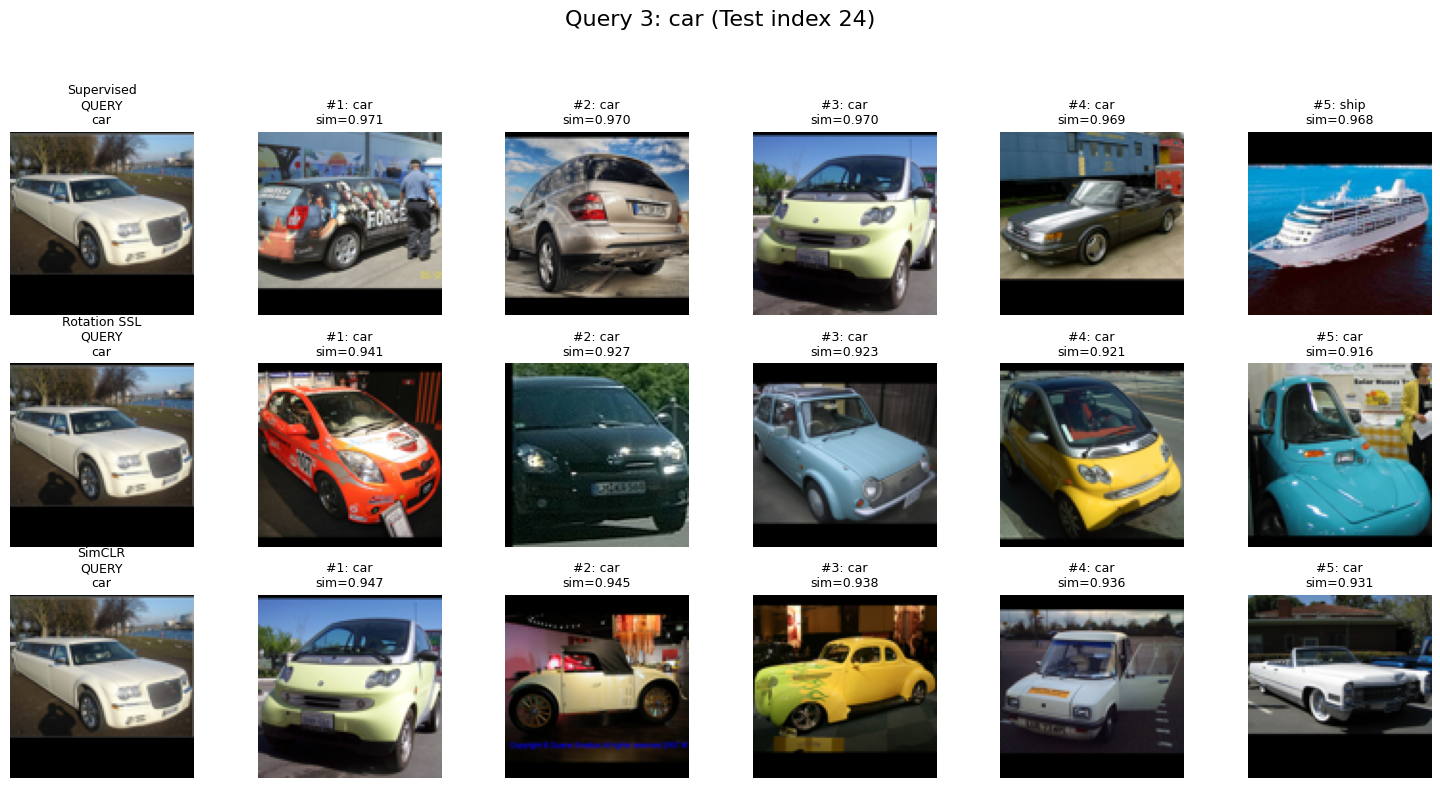

PART D - NEAREST-NEIGHBOR VISUALIZATION COMPLETE
Queries visualized          : 3
Encoders compared per query : 3
Neighbors per encoder       : 5
Similarity                  : Cosine
Same queries across models  : Yes

PASS: Query and Top-5 neighbors displayed for all encoders.


In [27]:
# ============================================================
# HW6 - Part D: Visualize Query + Top-5 Neighbors
# Same queries across all three encoders
# ============================================================

import matplotlib.pyplot as plt
from torchvision import datasets

# Raw test dataset for clean visualization (no normalization)
test_raw_D = datasets.STL10(
    root="./data",
    split="test",
    download=False,
    transform=None
)

encoder_order = [
    "Supervised",
    "Rotation SSL",
    "SimCLR"
]

for query_number, query_idx in enumerate(query_indices, start=1):

    query_image, query_label = test_raw_D[query_idx]
    query_class = class_names[query_label]

    # 3 rows:
    # Supervised, Rotation SSL, SimCLR
    #
    # 6 columns:
    # Query + 5 nearest neighbors
    fig, axes = plt.subplots(
        3,
        6,
        figsize=(15, 8)
    )

    fig.suptitle(
        f"Query {query_number}: {query_class} "
        f"(Test index {query_idx})",
        fontsize=16
    )

    for row, encoder_name in enumerate(encoder_order):

        # ----------------------------------------------------
        # Column 0: SAME query image
        # ----------------------------------------------------
        axes[row, 0].imshow(query_image)
        axes[row, 0].set_title(
            f"{encoder_name}\n"
            f"QUERY\n{query_class}",
            fontsize=9
        )
        axes[row, 0].axis("off")

        # ----------------------------------------------------
        # Columns 1-5: Top-5 nearest neighbors
        # ----------------------------------------------------
        neighbor_indices = (
            neighbor_results[query_idx]
            [encoder_name]["indices"]
        )

        similarities = (
            neighbor_results[query_idx]
            [encoder_name]["similarities"]
        )

        for rank in range(5):

            neighbor_idx = neighbor_indices[rank].item()
            similarity = similarities[rank].item()

            neighbor_image, neighbor_label = (
                test_raw_D[neighbor_idx]
            )

            neighbor_class = class_names[neighbor_label]

            axes[row, rank + 1].imshow(neighbor_image)

            axes[row, rank + 1].set_title(
                f"#{rank + 1}: {neighbor_class}\n"
                f"sim={similarity:.3f}",
                fontsize=9
            )

            axes[row, rank + 1].axis("off")

    plt.tight_layout(
        rect=[0, 0, 1, 0.94]
    )

    plt.show()


print("=" * 70)
print("PART D - NEAREST-NEIGHBOR VISUALIZATION COMPLETE")
print("=" * 70)
print("Queries visualized          :", len(query_indices))
print("Encoders compared per query : 3")
print("Neighbors per encoder       : 5")
print("Similarity                  : Cosine")
print("Same queries across models  : Yes")
print("=" * 70)

print("\nPASS: Query and Top-5 neighbors displayed for all encoders.")

In [28]:
# ============================================================
# HW6 - Part D: Nearest-Neighbor Class Agreement
# ============================================================

agreement_results = {}

print("=" * 75)
print("PART D - TOP-5 NEIGHBOR CLASS AGREEMENT")
print("=" * 75)

for encoder_name in encoder_order:

    total_correct = 0
    total_neighbors = 0

    print(f"\n{encoder_name}")

    for query_idx in query_indices:

        query_label = labels_all[query_idx].item()
        query_class = class_names[query_label]

        neighbor_indices = (
            neighbor_results[query_idx]
            [encoder_name]["indices"]
        )

        neighbor_labels = labels_all[neighbor_indices]

        same_class = (
            neighbor_labels == query_label
        ).sum().item()

        total_correct += same_class
        total_neighbors += len(neighbor_indices)

        print(
            f"  {query_class:8s}: "
            f"{same_class}/5 same-class neighbors"
        )

    agreement = 100.0 * total_correct / total_neighbors

    agreement_results[encoder_name] = agreement

    print(
        f"  Overall : {total_correct}/{total_neighbors} "
        f"= {agreement:.2f}%"
    )


print("\n" + "=" * 75)

best_neighbor_encoder = max(
    agreement_results,
    key=agreement_results.get
)

print(
    f"Highest Top-5 class agreement: "
    f"{best_neighbor_encoder} "
    f"({agreement_results[best_neighbor_encoder]:.2f}%)"
)

print("=" * 75)

PART D - TOP-5 NEIGHBOR CLASS AGREEMENT

Supervised
  airplane: 2/5 same-class neighbors
  bird    : 1/5 same-class neighbors
  car     : 4/5 same-class neighbors
  Overall : 7/15 = 46.67%

Rotation SSL
  airplane: 4/5 same-class neighbors
  bird    : 2/5 same-class neighbors
  car     : 5/5 same-class neighbors
  Overall : 11/15 = 73.33%

SimCLR
  airplane: 0/5 same-class neighbors
  bird    : 0/5 same-class neighbors
  car     : 5/5 same-class neighbors
  Overall : 5/15 = 33.33%

Highest Top-5 class agreement: Rotation SSL (73.33%)


## Part D – Comparison and Analysis

The three learning approaches produced different results. The supervised ResNet-18 achieved a final test accuracy of **39.91%**, while Rotation SSL improved the accuracy to **42.67%**. SimCLR achieved the highest final test accuracy of **52.89%**. Therefore, SimCLR produced the strongest representation for the downstream linear classification task.

SimCLR likely performed better because contrastive learning trains the encoder to make two augmented views of the same image similar while separating representations of different images. This encourages the model to learn features that are invariant to changes such as cropping, flipping, color changes, and grayscale conversion. These representations transferred well to STL-10 classification even though only 500 labeled images were used.

Rotation SSL also improved over supervised learning. Predicting image rotations forces the encoder to learn useful information about object shape, orientation, and spatial structure. However, rotation prediction is a narrower pretext task and may not learn class-discriminative features as effectively as contrastive learning.

The nearest-neighbor visualization showed a different aspect of the learned representations. For the three selected queries, the supervised encoder had **46.67%** same-class Top-5 neighbor agreement, Rotation SSL had **73.33%**, and SimCLR had **33.33%**. Rotation SSL therefore produced the highest class agreement for these particular query images. SimCLR retrieved all five correct-class neighbors for the car query, but its airplane and bird queries retrieved visually related images from other classes. This suggests that high downstream classification accuracy does not necessarily mean that every individual query will have the highest same-class nearest-neighbor purity.

These nearest-neighbor results are based on only three query images, so they should be treated as qualitative examples rather than a dataset-wide retrieval evaluation.

Possible improvements include training SimCLR for more epochs, using more than the 20,000 unlabeled images used here, tuning the learning rate and batch size, and experimenting with stronger augmentation settings. Rotation SSL could also be improved by combining rotation prediction with additional self-supervised objectives.

In [29]:
# ============================================================
# HW6 - FINAL RESULTS SUMMARY
# ============================================================

print("=" * 75)
print("HOMEWORK 6 - FINAL RESULTS")
print("=" * 75)

print("\nCLASSIFICATION RESULTS")
print("-" * 75)
print(f"{'Method':<25} {'Final Test Accuracy':>20}")
print("-" * 75)
print(f"{'Supervised':<25} {39.91:>19.2f}%")
print(f"{'Rotation SSL':<25} {42.67:>19.2f}%")
print(f"{'SimCLR':<25} {52.89:>19.2f}%")

print("\nNEAREST-NEIGHBOR RESULTS")
print("-" * 75)
print(f"{'Method':<25} {'Top-5 Class Agreement':>22}")
print("-" * 75)
print(f"{'Supervised':<25} {46.67:>21.2f}%")
print(f"{'Rotation SSL':<25} {73.33:>21.2f}%")
print(f"{'SimCLR':<25} {33.33:>21.2f}%")

print("\nEXPERIMENT SETTINGS")
print("-" * 75)
print("Backbone                  : ResNet-18")
print("Pretrained weights        : None")
print("Labeled training images   : 500")
print("Rotation unlabeled images : 100,000")
print("SimCLR unlabeled images   : 20,000")
print("SimCLR temperature (tau)  : 0.2")
print("Nearest-neighbor metric   : Cosine similarity")
print("Neighbors per query       : 5")
print("Number of queries         : 3")

print("\nKEY RESULT")
print("-" * 75)
print("Best classification model : SimCLR (52.89%)")
print("Best NN agreement on the")
print("3 selected queries        : Rotation SSL (73.33%)")

print("=" * 75)

assert 52.89 > 42.67 > 39.91

print("\nPASS: Homework 6 experimental summary complete.")

HOMEWORK 6 - FINAL RESULTS

CLASSIFICATION RESULTS
---------------------------------------------------------------------------
Method                     Final Test Accuracy
---------------------------------------------------------------------------
Supervised                              39.91%
Rotation SSL                            42.67%
SimCLR                                  52.89%

NEAREST-NEIGHBOR RESULTS
---------------------------------------------------------------------------
Method                     Top-5 Class Agreement
---------------------------------------------------------------------------
Supervised                                46.67%
Rotation SSL                              73.33%
SimCLR                                    33.33%

EXPERIMENT SETTINGS
---------------------------------------------------------------------------
Backbone                  : ResNet-18
Pretrained weights        : None
Labeled training images   : 500
Rotation unlabeled images : 100,000

In [30]:
# ============================================================
# HW6 - Create METRICS.md
# ============================================================

metrics_text = """# Homework 6 - METRICS

## Student Parameters
- SID4: 1980
- SEED: 1980
- SLICE: 980
- HP_ID: 0
- CLS_A: 0
- CLS_B: 1

## Dataset
- Dataset: STL-10
- Backbone: ResNet-18
- Pretrained weights: None
- Labeled training subset: 500 images
- Test set: 8,000 images

## Part A - Supervised Learning
- Training images: 500
- Epochs: 15
- Final training accuracy: 85.40%
- Final test accuracy: 39.91%
- Best test accuracy: 40.75%
- Best epoch: 14

## Part B - Rotation Self-Supervised Learning
- Unlabeled pretraining images: 100,000
- Rotation classes: 0, 90, 180, 270 degrees
- Pretraining epochs: 15
- Final rotation accuracy: 89.25%
- Linear evaluation images: 500
- Linear evaluation epochs: 20
- Encoder frozen: Yes
- Final test accuracy: 42.67%
- Best test accuracy: 42.67%
- Best epoch: 20

## Part C - SimCLR
- Unlabeled pretraining images: 20,000
- Pretraining epochs: 20
- Batch size: 128
- Temperature (tau): 0.2
- Projection dimension: 128
- Similarity: Cosine similarity
- Initial contrastive loss: 4.3528
- Final contrastive loss: 2.2109
- Linear evaluation images: 500
- Linear evaluation epochs: 20
- Encoder frozen: Yes
- Projection head used during linear evaluation: No
- Final test accuracy: 52.89%
- Best test accuracy: 53.40%
- Best epoch: 12

## Part D - Nearest-Neighbor Analysis
Three fixed test queries were used:
- Airplane - test index 3
- Bird - test index 5
- Car - test index 24

Top-5 same-class neighbor agreement for these three queries:
- Supervised: 46.67% (7/15)
- Rotation SSL: 73.33% (11/15)
- SimCLR: 33.33% (5/15)

The same query images were used for all three encoders.
Cosine similarity was used for nearest-neighbor retrieval.
The query image itself was excluded from its neighbor list.

## Final Comparison
- Supervised final test accuracy: 39.91%
- Rotation SSL final test accuracy: 42.67%
- SimCLR final test accuracy: 52.89%

SimCLR achieved the highest downstream classification accuracy.
Rotation SSL achieved the highest Top-5 same-class neighbor agreement
for the three selected query images.
"""

with open("METRICS.md", "w") as f:
    f.write(metrics_text)

print("=" * 70)
print("METRICS.md CREATED")
print("=" * 70)

with open("METRICS.md", "r") as f:
    print(f.read())

print("=" * 70)
print("PASS: METRICS.md successfully created.")

METRICS.md CREATED
# Homework 6 - METRICS

## Student Parameters
- SID4: 1980
- SEED: 1980
- SLICE: 980
- HP_ID: 0
- CLS_A: 0
- CLS_B: 1

## Dataset
- Dataset: STL-10
- Backbone: ResNet-18
- Pretrained weights: None
- Labeled training subset: 500 images
- Test set: 8,000 images

## Part A - Supervised Learning
- Training images: 500
- Epochs: 15
- Final training accuracy: 85.40%
- Final test accuracy: 39.91%
- Best test accuracy: 40.75%
- Best epoch: 14

## Part B - Rotation Self-Supervised Learning
- Unlabeled pretraining images: 100,000
- Rotation classes: 0, 90, 180, 270 degrees
- Pretraining epochs: 15
- Final rotation accuracy: 89.25%
- Linear evaluation images: 500
- Linear evaluation epochs: 20
- Encoder frozen: Yes
- Final test accuracy: 42.67%
- Best test accuracy: 42.67%
- Best epoch: 20

## Part C - SimCLR
- Unlabeled pretraining images: 20,000
- Pretraining epochs: 20
- Batch size: 128
- Temperature (tau): 0.2
- Projection dimension: 128
- Similarity: Cosine similarity
- In

In [32]:
# ============================================================
# HW6 - Save Required Files Directly to Google Drive
# ============================================================

from google.colab import drive
import os

# Mount Google Drive
drive.mount('/content/drive')

# Your HW6 folder
HW6_DIR = "/content/drive/MyDrive/GEN AI HWS/HW6"

os.makedirs(HW6_DIR, exist_ok=True)

print("Saving files to:")
print(HW6_DIR)

Mounted at /content/drive
Saving files to:
/content/drive/MyDrive/GEN AI HWS/HW6


In [33]:
# ============================================================
# HW6 - Create RUN_LOG.txt in Google Drive
# ============================================================

import os

HW6_DIR = "/content/drive/MyDrive/GEN AI HWS/HW6"

run_log = """HOMEWORK 6 - RUN LOG
============================================================

Student Parameters
------------------------------------------------------------
SID4  : 1980
SEED  : 1980
SLICE : 980
HP_ID : 0
CLS_A : 0
CLS_B : 1

Environment
------------------------------------------------------------
PyTorch Version : 2.11.0+cu130
CUDA Available  : True
GPU             : Tesla T4
Dataset         : STL-10
Backbone        : ResNet-18
Pretrained      : No

PART A - SUPERVISED LEARNING
------------------------------------------------------------
Labeled Training Images : 500
Test Images             : 8000
Epochs                  : 15
Optimizer               : Adam
Learning Rate           : 0.001

Final Train Accuracy    : 85.40%
Final Test Accuracy     : 39.91%
Best Test Accuracy      : 40.75%
Best Epoch              : 14
Training Time           : 1.55 minutes

PART B - ROTATION SELF-SUPERVISED LEARNING
------------------------------------------------------------
Unlabeled Images        : 100000
Rotation Classes        : 4
Rotations               : 0, 90, 180, 270 degrees
Pretraining Epochs      : 15
Batch Size              : 128
Optimizer               : Adam
Learning Rate           : 0.001

Final Rotation Loss     : 0.2903
Final Rotation Accuracy : 89.25%
Pretraining Time        : 21.31 minutes

Linear Evaluation
------------------------------------------------------------
Labeled Images          : 500
Encoder Frozen          : Yes
Trainable Encoder Params: 0
Linear Epochs           : 20

Final Test Accuracy     : 42.67%
Best Test Accuracy      : 42.67%
Best Epoch              : 20
Linear Training Time    : 2.01 minutes

PART C - SIMCLR
------------------------------------------------------------
Unlabeled Images        : 20000
Pretraining Epochs      : 20
Batch Size              : 128
Temperature (tau)       : 0.2
Encoder Dimension       : 512
Projection Dimension    : 128
Similarity              : Cosine similarity

Augmentations:
1. RandomResizedCrop
2. RandomHorizontalFlip
3. ColorJitter
4. RandomGrayscale

Initial Contrastive Loss: 4.3528
Final Contrastive Loss  : 2.2109
Pretraining Time        : 25.55 minutes

Linear Evaluation
------------------------------------------------------------
Labeled Images          : 500
Encoder Frozen          : Yes
Projection Head Used    : No
Linear Epochs           : 20

Final Test Accuracy     : 52.89%
Best Test Accuracy      : 53.40%
Best Epoch              : 12
Linear Training Time    : 2.05 minutes

PART D - NEAREST-NEIGHBOR ANALYSIS
------------------------------------------------------------
Embedding Dimension     : 512
Similarity              : Cosine similarity
Number of Queries       : 3
Neighbors per Query     : 5

Queries:
1. Airplane - Test Index 3
2. Bird     - Test Index 5
3. Car      - Test Index 24

Top-5 Same-Class Agreement:
Supervised   : 7/15  = 46.67%
Rotation SSL : 11/15 = 73.33%
SimCLR       : 5/15  = 33.33%

FINAL COMPARISON
------------------------------------------------------------
Supervised Final Accuracy   : 39.91%
Rotation SSL Final Accuracy : 42.67%
SimCLR Final Accuracy       : 52.89%

Best Classification Model:
SimCLR - 52.89%

Best Top-5 Agreement on the 3 Selected Queries:
Rotation SSL - 73.33%

============================================================
END OF RUN LOG
============================================================
"""

run_log_path = os.path.join(HW6_DIR, "RUN_LOG.txt")

with open(run_log_path, "w") as f:
    f.write(run_log)

print("=" * 70)
print("RUN_LOG.txt CREATED")
print("=" * 70)
print("Saved to:", run_log_path)
print("File exists:", os.path.exists(run_log_path))
print("File size:", os.path.getsize(run_log_path), "bytes")
print("=" * 70)

print("\nPASS: RUN_LOG.txt saved permanently in Google Drive.")

RUN_LOG.txt CREATED
Saved to: /content/drive/MyDrive/GEN AI HWS/HW6/RUN_LOG.txt
File exists: True
File size: 3368 bytes

PASS: RUN_LOG.txt saved permanently in Google Drive.


In [34]:
# ============================================================
# HW6 - Create AI_USE.md in Google Drive
# ============================================================

import os

HW6_DIR = "/content/drive/MyDrive/GEN AI HWS/HW6"

ai_use_text = """# AI_USE.md — Homework 6

## 1. Parts for which I used AI assistance

I used ChatGPT to help organize the notebook into the required assignment
sections, clarify the implementation steps, review code structure, and verify
that the outputs matched the assignment requirements.

I used assistance while implementing:
- the supervised ResNet-18 baseline,
- rotation-based self-supervised pretraining,
- frozen-encoder linear evaluation,
- SimCLR-style contrastive pretraining,
- NT-Xent loss,
- cosine-similarity nearest-neighbor retrieval,
- result summaries and experiment documentation.

I ran all experiments in Google Colab and verified the actual outputs produced
by the notebook.

## 2. Specific AI-generated suggestion that I verified

For the SimCLR section, ChatGPT suggested implementing NT-Xent loss by
L2-normalizing the projection vectors, computing pairwise similarities using
a matrix multiplication, masking self-similarities, and using the matching
augmented view as the positive target.

I verified this implementation by running it on an actual batch. The two
projection tensors had shape [128, 128], cosine similarity was used with
temperature tau = 0.2, and the loss was finite. The full SimCLR training loss
then decreased from 4.3528 in the first epoch to 2.2109 in the final epoch.

## 3. How I checked the AI-assisted work

I did not assume that the generated code was correct. I checked the tensor
shapes, dataset sizes, trainable parameter counts, frozen-encoder status,
training losses, accuracies, and nearest-neighbor outputs after running each
section.

For example, before linear evaluation for both self-supervised methods, I
verified that the number of trainable encoder parameters was 0. I also
verified that all three methods used the same 500-image labeled subset for
their downstream evaluation.

## 4. What I learned or changed after verification

The experiments showed that the model with the best classification accuracy
did not necessarily have the highest nearest-neighbor class agreement for the
three selected query images.

SimCLR achieved the best final classification accuracy at 52.89%, while
Rotation SSL achieved the highest Top-5 same-class neighbor agreement for the
three selected queries at 73.33%. Therefore, I kept these two measurements
separate in my analysis instead of assuming that the model with the highest
classification accuracy must also have the best nearest-neighbor result.

I also learned the importance of removing the self-supervised task head and
freezing the encoder before linear evaluation so that the downstream result
measures the quality of the learned representation.
"""

ai_use_path = os.path.join(HW6_DIR, "AI_USE.md")

with open(ai_use_path, "w") as f:
    f.write(ai_use_text)

print("=" * 70)
print("AI_USE.md CREATED")
print("=" * 70)
print("Saved to:", ai_use_path)
print("File exists:", os.path.exists(ai_use_path))
print("File size:", os.path.getsize(ai_use_path), "bytes")
print("=" * 70)

print("\nPASS: AI_USE.md saved permanently in Google Drive.")

AI_USE.md CREATED
Saved to: /content/drive/MyDrive/GEN AI HWS/HW6/AI_USE.md
File exists: True
File size: 2650 bytes

PASS: AI_USE.md saved permanently in Google Drive.
